## TRADITIONAL MACHINE LEARNING MODELS

In [1]:
# -*- coding: utf-8 -*-
"""Machine Learning Algorithms.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1OunltsoW6bU8pQxg6tvIYLKmcvcv92qG

## IMPORT THE DATA
"""

# -*- coding: utf-8 -*-
"""Machine Learning Algorithms.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1OunltsoW6bU8pQxg6tvIYLKmcvcv92qG
"""

# -*- coding: utf-8 -*-
"""MachineLearningAlgos.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1A5NwaKoyNvPAYFttnciZfxYoj5m3O_qL

Proposed research framework

1. 100K Student Depessin Dataset
2. Data Split
4. SMOTE on Training data
2. Data preprocessing and quality checks- missing values, duplicates, encoding, outliers, scaling
3. Statistical analysis: t-test.
Feature selection: RFE.
4. Traditional ML -  Random Forest, XGBoost, LightGBM, SVM, Logistic Regression, CatBoost, KNN, Gaussian Naive Bayes, MLP
5. Model evaluation - Stratified Cross validation, accuracy, precision, Recall. F1 score, auc, specificity
6. Explanaible analysis - SHAP
"""

!pip install catboost -q

##IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix, make_scorer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import ttest_ind

"""## DATA PREPROCESSING"""

## DATAPROCESSING AND QUALITY CHECKS

# Load the three separate datasets
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
validation = pd.read_csv("validation.csv")

# Separate features and target variable
X_train = train.drop("Depression", axis=1)
y_train = train["Depression"]

X_test = test.drop("Depression", axis=1)
y_test = test["Depression"]

X_val = validation.drop("Depression", axis=1)
y_val = validation["Depression"]

In [2]:
## DATAPROCESSING AND QUALITY CHECKS

# Missing values
print("Missing values in Training data:")
print(X_train.isnull().sum())

print("\nMissing values in Test data:")
print(X_test.isnull().sum())

print("\nMissing values in Validation data:")
print(X_val.isnull().sum())


# Duplicate rows
print("\nDuplicate rows in Training data:", X_train.duplicated().sum())
print("Duplicate rows in Test data:", X_test.duplicated().sum())
print("Duplicate rows in Validation data:", X_val.duplicated().sum())


# Remove duplicate rows from each dataset
duplicate_rows_train = X_train.index[X_train.duplicated()]
X_train = X_train.drop(index=duplicate_rows_train)
y_train = y_train.loc[X_train.index]

duplicate_rows_test = X_test.index[X_test.duplicated()]
X_test = X_test.drop(index=duplicate_rows_test)
y_test = y_test.loc[X_test.index]

duplicate_rows_val = X_val.index[X_val.duplicated()]
X_val = X_val.drop(index=duplicate_rows_val)
y_val = y_val.loc[X_val.index]


# Outlier check using the IQR method (numeric columns)
numeric_columns = X_train.select_dtypes(include=np.number).columns

for column in numeric_columns:
    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    print(column, "Outliers:",
          ((X_train[column] < lower_limit) |
           (X_train[column] > upper_limit)).sum())

print("\nData Processing and Quality Checks Completed")

# Separate numeric and categorical columns
numeric_columns = X_train.select_dtypes(include=np.number).columns
categorical_columns = X_train.select_dtypes(exclude=np.number).columns

# Missing value treatment: fit on training data only
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train[numeric_columns] = numeric_imputer.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = numeric_imputer.transform(X_test[numeric_columns])
X_val[numeric_columns] = numeric_imputer.transform(X_val[numeric_columns])

if len(categorical_columns) > 0:
    X_train[categorical_columns] = categorical_imputer.fit_transform(X_train[categorical_columns])
    X_test[categorical_columns] = categorical_imputer.transform(X_test[categorical_columns])
    X_val[categorical_columns] = categorical_imputer.transform(X_val[categorical_columns])

# Encoding categorical variables
X_train = pd.get_dummies(X_train, columns=categorical_columns)
X_test = pd.get_dummies(X_test, columns=categorical_columns)
X_val = pd.get_dummies(X_val, columns=categorical_columns)

# Make test and validation columns match training columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)

# Scaling: fit on training data only
sc = MinMaxScaler()
X_train = pd.DataFrame(sc.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(sc.transform(X_test), columns=X_test.columns, index=X_test.index)
X_val = pd.DataFrame(sc.transform(X_val), columns=X_val.columns, index=X_val.index)

print("Preprocessing completed")

Missing values in Training data:
Age                   0
Gender                0
Department            0
CGPA                  0
Sleep_Duration        0
Study_Hours           0
Social_Media_Hours    0
Physical_Activity     0
Stress_Level          0
dtype: int64

Missing values in Test data:
Age                   0
Gender                0
Department            0
CGPA                  0
Sleep_Duration        0
Study_Hours           0
Social_Media_Hours    0
Physical_Activity     0
Stress_Level          0
dtype: int64

Missing values in Validation data:
Age                   0
Gender                0
Department            0
CGPA                  0
Sleep_Duration        0
Study_Hours           0
Social_Media_Hours    0
Physical_Activity     0
Stress_Level          0
dtype: int64

Duplicate rows in Training data: 0
Duplicate rows in Test data: 0
Duplicate rows in Validation data: 0
Age Outliers: 0
CGPA Outliers: 0
Sleep_Duration Outliers: 259
Study_Hours Outliers: 286
Social_Media_Hours Out

In [3]:
""" ## FEATURE ENGINEERING"""

## SMOTE ON TRAINING DATA

print("Class distribution before SMOTE:")
print(y_train.value_counts())

sm = SMOTE(random_state=42)
X_train_smote, y_train_smote = sm.fit_resample(X_train, y_train)

print("Class distribution after SMOTE:")
print(pd.Series(y_train_smote).value_counts())

## T-TEST

# t-test for numeric predictors against a binary target
t_test_results = []

for column in X_train.select_dtypes(include=np.number).columns:
    group_0 = X_train.loc[np.asarray(y_train) == 0, column]
    group_1 = X_train.loc[np.asarray(y_train) == 1, column]

    t_stat, p_value = ttest_ind(group_0, group_1, equal_var=False, nan_policy="omit")
    t_test_results.append([column, t_stat, p_value])

t_test_df = pd.DataFrame(t_test_results, columns=["Feature", "T-Statistic", "P-Value"])
t_test_df = t_test_df.sort_values("P-Value")
t_test_df

## FEATURE SELECTION - RFE

np.random.seed(42)

rfe_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    solver="liblinear"
)
rfe = RFE(estimator=rfe_model, n_features_to_select=min(15, X_train_smote.shape[1]))
rfe.fit(X_train_smote, y_train_smote)

selected_features = X_train_smote.columns[rfe.support_]
print("Selected Features:")
print(selected_features)

X_train_selected = X_train_smote[selected_features]
X_test_selected = X_test[selected_features]
X_val_selected = X_val[selected_features]

"""## MODEL TRAINING (Train set) + TESTING(Test set)"""

Class distribution before SMOTE:
Depression
False    62957
True      7043
Name: count, dtype: int64
Class distribution after SMOTE:
Depression
False    62957
True     62957
Name: count, dtype: int64
Selected Features:
Index(['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours',
       'Physical_Activity', 'Stress_Level', 'Gender_Female', 'Gender_Male',
       'Department_Arts', 'Department_Business', 'Department_Engineering',
       'Department_Medical', 'Department_Science'],
      dtype='object')


'## MODEL TRAINING (Train set) + TESTING(Test set)'

In [4]:
## STRATIFIED CROSS VALIDATION + EVALUATION METRICS

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else 0

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted",
    "auc": "roc_auc",
    "specificity": make_scorer(specificity_score)
}

## TRADITIONAL ML

models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss"),
    "LightGBM": lgb.LGBMClassifier(random_state=42, verbosity=-1, class_weight='balanced'),
    # Linear SVM is far faster than SVC(kernel="rbf") on ~100K rows.
    # CalibratedClassifierCV adds predict_proba so AUC still works.
    "SVM": CalibratedClassifierCV(LinearSVC(random_state=42, max_iter=5000), cv=3),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_seed=42,auto_class_weights='Balanced'),
    "KNN": KNeighborsClassifier(),
    "Gaussian Naive Bayes": GaussianNB()
}

model_results = []

for model_name, model in models.items():
    print("Model:", model_name)

    model_pipeline = Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    cv_results = cross_validate(
        model_pipeline,
        X_train[selected_features],
        y_train,
        cv=kf,
        scoring=scoring,
        n_jobs=-1
    )

    model_pipeline.fit(X_train[selected_features], y_train)

    pred_test = model_pipeline.predict(X_test[selected_features])
    pred_proba = model_pipeline.predict_proba(X_test[selected_features])[:, 1]

    accur = accuracy_score(y_test, pred_test)
    prec = precision_score(y_test, pred_test, average="weighted", zero_division=0)
    rec = recall_score(y_test, pred_test, average="weighted", zero_division=0)
    f1 = f1_score(y_test, pred_test, average="weighted", zero_division=0)
    auc = roc_auc_score(y_test, pred_proba)
    specificity = specificity_score(y_test, pred_test)

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, pred_test))
    print("Accuracy:", accur)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1 Score:", f1)
    print("AUC:", auc)
    print("Specificity:", specificity)

    model_results.append([
        model_name,
        np.mean(cv_results["test_accuracy"]),
        np.mean(cv_results["test_precision"]),
        np.mean(cv_results["test_recall"]),
        np.mean(cv_results["test_f1"]),
        np.mean(cv_results["test_auc"]),
        np.mean(cv_results["test_specificity"]),
        accur, prec, rec, f1, auc, specificity
    ])

model_results_df = pd.DataFrame(model_results, columns=[
    "Model", "CV Accuracy", "CV Precision", "CV Recall", "CV F1",
    "CV AUC", "CV Specificity", "Test Accuracy", "Test Precision",
    "Test Recall", "Test F1", "Test AUC", "Test Specificity"
])
model_results_df

Model: Random Forest
Confusion Matrix:
[[17070   917]
 [ 1719   294]]
Accuracy: 0.8682
Precision: 0.8415039971425909
Recall: 0.8682
F1 Score: 0.8532438892610403
AUC: 0.6858970646432812
Specificity: 0.9490187357535999
Model: XGBoost
Confusion Matrix:
[[17837   150]
 [ 1907   106]]
Accuracy: 0.89715
Precision: 0.8541604974929092
Recall: 0.89715
F1 Score: 0.859723736078689
AUC: 0.6959041816119833
Specificity: 0.9916606437982988
Model: LightGBM
Confusion Matrix:
[[17820   167]
 [ 1885   128]]
Accuracy: 0.8974
Precision: 0.8569891442849832
Recall: 0.8974
F1 Score: 0.861552203622134
AUC: 0.6953752628816676
Specificity: 0.990715516762106
Model: SVM
Confusion Matrix:
[[11102  6885]
 [  670  1343]]
Accuracy: 0.62225
Precision: 0.8645921620640656
Recall: 0.62225
F1 Score: 0.697427905950087
AUC: 0.6812171654247945
Specificity: 0.6172235503419136
Model: Logistic Regression
Confusion Matrix:
[[11100  6887]
 [  671  1342]]
Accuracy: 0.6221
Precision: 0.864497182147726
Recall: 0.6221
F1 Score: 0.6973

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,CV Specificity,Test Accuracy,Test Precision,Test Recall,Test F1,Test AUC,Test Specificity
0,Random Forest,0.868557,0.842531,0.868557,0.853967,0.684418,0.948822,0.86820,0.841504,0.86820,0.853244,0.685897,0.949019
1,XGBoost,0.896571,0.851691,0.896571,0.858836,0.693246,0.991391,0.89715,0.854160,0.89715,0.859724,0.695904,0.991661
2,LightGBM,0.896943,0.855241,0.896943,0.860901,0.696929,0.990470,0.89740,0.856989,0.89740,0.861552,0.695375,0.990716
3,SVM,0.625029,0.867753,0.625029,0.699657,0.685596,0.618295,0.62225,0.864592,0.62225,0.697428,0.681217,0.617224
4,Logistic Regression,0.625114,0.867740,0.625114,0.699728,0.685599,0.618406,0.62210,0.864497,0.62210,0.697307,0.681379,0.617112
5,CatBoost,0.898143,0.854570,0.898143,0.857671,0.695034,0.994552,0.89835,0.854954,0.89835,0.857246,0.698267,0.995163
6,KNN,0.680500,0.840330,0.680500,0.740663,0.596032,0.707721,0.68055,0.839167,0.68055,0.740549,0.594468,0.708734
7,Gaussian Naive Bayes,0.632800,0.864965,0.632800,0.705927,0.677674,0.629700,0.63410,0.863925,0.63410,0.706957,0.679663,0.632012


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Specificity
0,CatBoost,0.8984,0.8550,0.8984,0.8572,0.6983,0.9952
1,XGBoost,0.8972,0.8542,0.8972,0.8597,0.6959,0.9917
2,LightGBM,0.8974,0.8570,0.8974,0.8616,0.6954,0.9907
3,Random Forest,0.8682,0.8415,0.8682,0.8532,0.6859,0.9490
4,Logistic Regression,0.6221,0.8645,0.6221,0.6973,0.6814,0.6171
5,SVM,0.6222,0.8646,0.6222,0.6974,0.6812,0.6172
6,Gaussian Naive Bayes,0.6341,0.8639,0.6341,0.7070,0.6797,0.6320
7,KNN,0.6806,0.8392,0.6806,0.7405,0.5945,0.7087


Test-set model comparison table saved successfully.


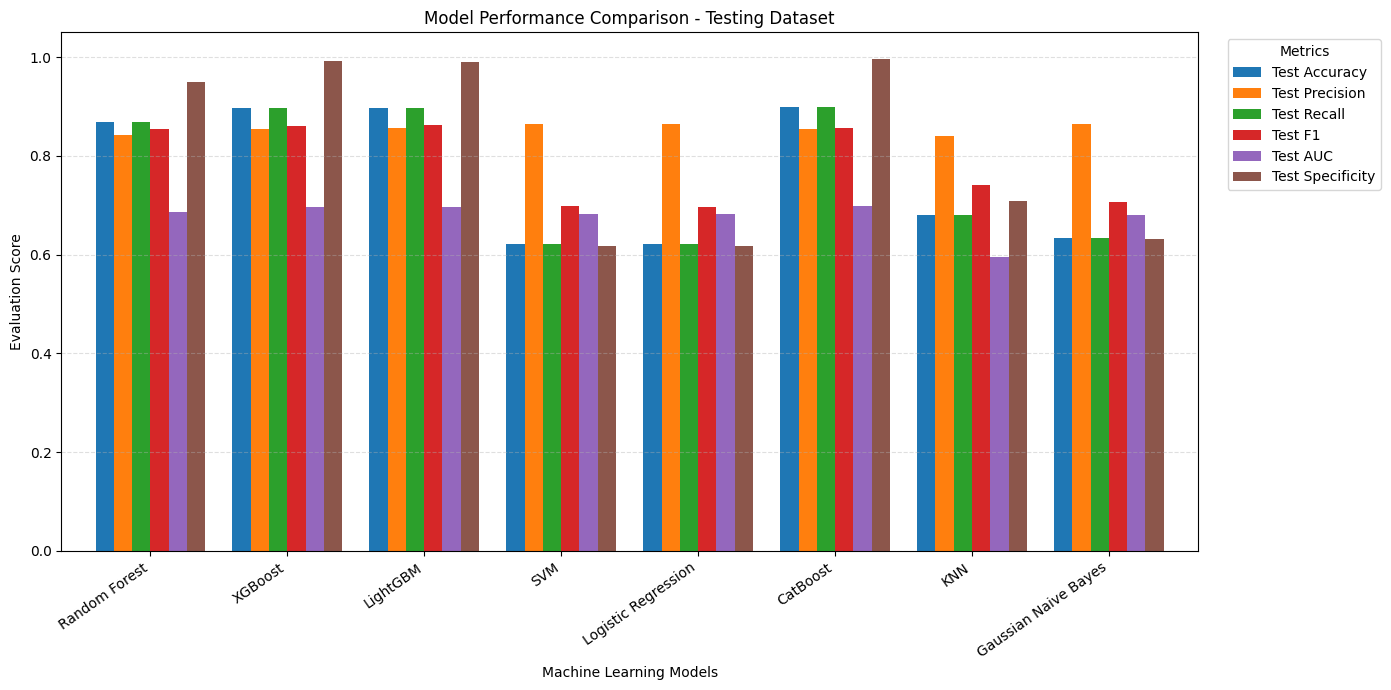

In [5]:
"""## MODEL COMPARISON WITH TEST SET"""
# ==========================================
# MODEL COMPARISON WITH TEST SET
# Traditional Machine Learning Algorithms
# ==========================================

# Extract test columns from the already computed model_results_df
test_columns = [
    "Model",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test AUC",
    "Test Specificity"
]
test_comparison_df = model_results_df[test_columns].copy()

# Rename columns to match the desired format
test_comparison_df = test_comparison_df.rename(columns={
    "Test Accuracy": "Accuracy",
    "Test Precision": "Precision",
    "Test Recall": "Recall",
    "Test F1": "F1-Score",
    "Test AUC": "ROC-AUC",
    "Test Specificity": "Specificity"
})

# Sort by ROC-AUC
test_comparison_df = test_comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

# Round values
test_comparison_df = test_comparison_df.round(4)

# Display table
display(test_comparison_df)

# Save table
test_comparison_df.to_csv(
    "ML_Test_Set_Model_Comparison.csv",
    index=False
)

test_comparison_df.to_excel(
    "ML_Test_Set_Model_Comparison.xlsx",
    index=False
)

print("Test-set model comparison table saved successfully.")

"""## MODEL COMPARISON CHART"""

import matplotlib.pyplot as plt

# Define the missing variables using the available model_results_df
test_comparison = model_results_df
metrics = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test AUC",
    "Test Specificity"
]

test_plot = test_comparison.set_index("Model")[metrics]

ax = test_plot.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Model Performance Comparison - Testing Dataset")
plt.xlabel("Machine Learning Models")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "Testing_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

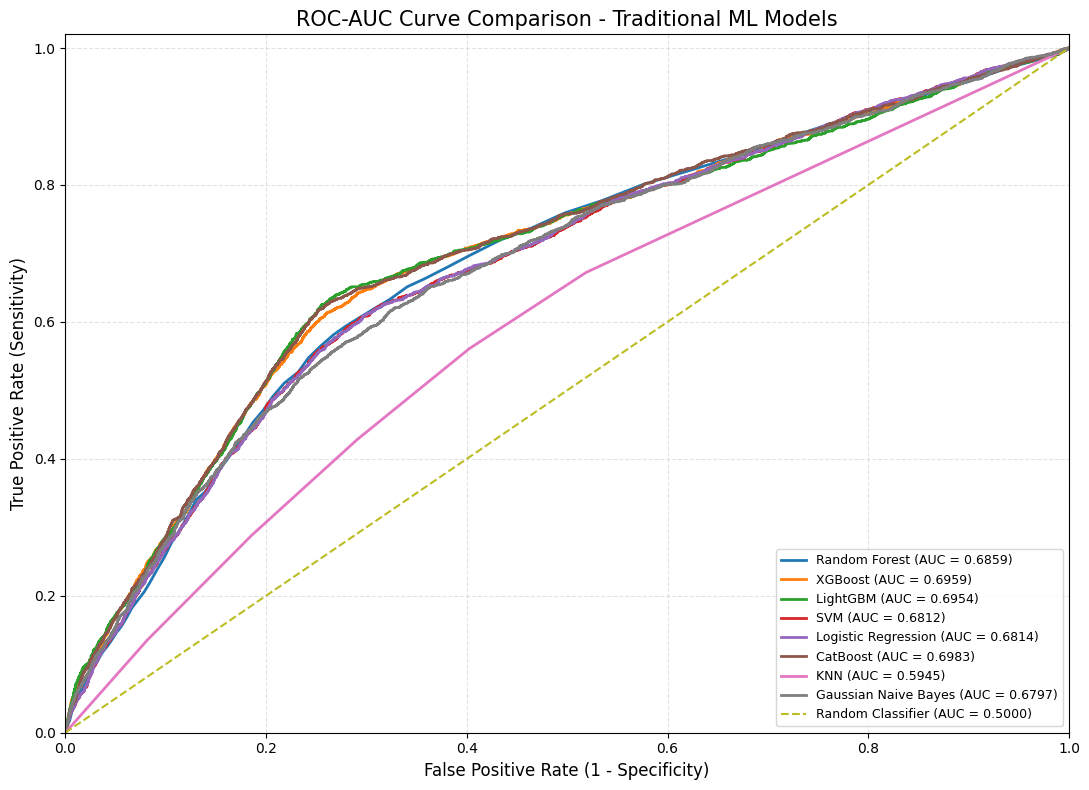


ROC-AUC MODEL COMPARISON


,Rank,Model,Test AUC
0,1,CatBoost,0.6983
1,2,XGBoost,0.6959
2,3,LightGBM,0.6954
3,4,Random Forest,0.6859
4,5,Logistic Regression,0.6814
5,6,SVM,0.6812
6,7,Gaussian Naive Bayes,0.6797
7,8,KNN,0.5945


In [6]:
# ==========================================
# ROC-AUC CURVE FOR ALL TRADITIONAL ML MODELS
# ==========================================

from sklearn.metrics import roc_curve, auc
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
OUTPUT_DIR = "."  # Defined output directory as the current directory to fix the NameError

# ------------------------------------------
# 1. Ensure all fitted models are available
# ------------------------------------------

if (
    "fitted_models" not in globals()
    or not all(name in fitted_models for name in models)
):

    fitted_models = {}

    for model_name, model in models.items():

        model_pipeline = Pipeline([
            ("smote", SMOTE(random_state=SEED)),
            ("model", model)
        ])

        model_pipeline.fit(
            X_train[selected_features],
            y_train
        )

        fitted_models[model_name] = model_pipeline


# ------------------------------------------
# 2. Plot ROC curves
# ------------------------------------------

plt.figure(figsize=(11, 8))

roc_results = []

for model_name, model_pipeline in fitted_models.items():

    # Get predicted probabilities for Depression = 1
    probabilities = model_pipeline.predict_proba(
        X_test[selected_features]
    )[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities,
        pos_label=1
    )

    # Calculate AUC
    model_auc = auc(fpr, tpr)

    roc_results.append([
        model_name,
        model_auc
    ])

    # Plot individual ROC curve
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {model_auc:.4f})"
    )


# ------------------------------------------
# 3. Random classifier reference line
# ------------------------------------------

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.5000)"
)


# ------------------------------------------
# 4. Graph formatting
# ------------------------------------------

plt.title(
    "ROC-AUC Curve Comparison - Traditional ML Models",
    fontsize=15
)

plt.xlabel(
    "False Positive Rate (1 - Specificity)",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate (Sensitivity)",
    fontsize=12
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.grid(
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()


# ------------------------------------------
# 5. Save graph
# ------------------------------------------

plt.savefig(
    f"{OUTPUT_DIR}/Combined_ROC_AUC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------
# 6. Create AUC comparison table
# ------------------------------------------

roc_results_df = pd.DataFrame(
    roc_results,
    columns=["Model", "Test AUC"]
)

roc_results_df = roc_results_df.sort_values(
    by="Test AUC",
    ascending=False
).reset_index(drop=True)

roc_results_df.insert(
    0,
    "Rank",
    range(1, len(roc_results_df) + 1)
)

print("\nROC-AUC MODEL COMPARISON")

display(roc_results_df.round(4))


# Save AUC results
roc_results_df.to_csv(
    f"{OUTPUT_DIR}/ROC_AUC_Comparison.csv",
    index=False
)

roc_results_df.to_excel(
    f"{OUTPUT_DIR}/ROC_AUC_Comparison.xlsx",
    index=False
)

In [7]:
"""## BEST MODEL BASED ON F1 AND RECALL"""

## IDENTIFY BEST MODEL USING TEST F1 AND RECALL

# Calculate ranks: highest scores receive rank 1
test_comparison["F1_Rank"] = test_comparison["Test F1"].rank(
    ascending=False, method="min"
)

test_comparison["Recall_Rank"] = test_comparison["Test Recall"].rank(
    ascending=False, method="min"
)

# Calculate average rank across all three metrics
test_comparison["Average_Rank"] = (
    test_comparison["F1_Rank"]
    + test_comparison["Recall_Rank"]
) / 3

# Sort by average rank
test_comparison = test_comparison.sort_values(
    by=["Average_Rank", "Test F1", "Test Recall"],
    ascending=[True, False, False]
).reset_index(drop=True)

# Add final ranking
test_comparison["Final_Rank"] = range(1, len(test_comparison) + 1)

print("MODEL COMPARISON USING TEST F1, AUC AND RECALL")
display(test_comparison.round(4))

# Select best model
best_model_name = test_comparison.iloc[0]["Model"]

# Ensure fitted_models dictionary exists and contains the models
if 'fitted_models' not in globals():
    fitted_models = {}

    for name, model in models.items():
        model_pipeline = Pipeline([
            ("smote", SMOTE(random_state=42)),
            ("model", model)
        ])

        model_pipeline.fit(
            X_train[selected_features],
            y_train
        )

        fitted_models[name] = model_pipeline

best_model = fitted_models[best_model_name]

print("\nBEST MODEL:", best_model_name)
print("Test F1:", test_comparison.iloc[0]["Test F1"])
print("Test Recall:", test_comparison.iloc[0]["Test Recall"])
print("Average Rank:", test_comparison.iloc[0]["Average_Rank"])

"""## VALIDATING USING BEST TEST MODEL"""

MODEL COMPARISON USING TEST F1, AUC AND RECALL


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV AUC,CV Specificity,Test Accuracy,Test Precision,Test Recall,Test F1,Test AUC,Test Specificity,F1_Rank,Recall_Rank,Average_Rank,Final_Rank
0,LightGBM,0.8969,0.8552,0.8969,0.8609,0.6969,0.9905,0.8974,0.8570,0.8974,0.8616,0.6954,0.9907,1.0,2.0,1.0000,1
1,CatBoost,0.8981,0.8546,0.8981,0.8577,0.6950,0.9946,0.8984,0.8550,0.8984,0.8572,0.6983,0.9952,3.0,1.0,1.3333,2
2,XGBoost,0.8966,0.8517,0.8966,0.8588,0.6932,0.9914,0.8972,0.8542,0.8972,0.8597,0.6959,0.9917,2.0,3.0,1.6667,3
3,Random Forest,0.8686,0.8425,0.8686,0.8540,0.6844,0.9488,0.8682,0.8415,0.8682,0.8532,0.6859,0.9490,4.0,4.0,2.6667,4
4,KNN,0.6805,0.8403,0.6805,0.7407,0.5960,0.7077,0.6806,0.8392,0.6806,0.7405,0.5945,0.7087,5.0,5.0,3.3333,5
5,Gaussian Naive Bayes,0.6328,0.8650,0.6328,0.7059,0.6777,0.6297,0.6341,0.8639,0.6341,0.7070,0.6797,0.6320,6.0,6.0,4.0000,6
6,SVM,0.6250,0.8678,0.6250,0.6997,0.6856,0.6183,0.6222,0.8646,0.6222,0.6974,0.6812,0.6172,7.0,7.0,4.6667,7
7,Logistic Regression,0.6251,0.8677,0.6251,0.6997,0.6856,0.6184,0.6221,0.8645,0.6221,0.6973,0.6814,0.6171,8.0,8.0,5.3333,8



BEST MODEL: LightGBM
Test F1: 0.861552203622134
Test Recall: 0.8974
Average Rank: 1.0


'## VALIDATING USING BEST TEST MODEL'

BEST MODEL PERFORMANCE ON VALIDATION DATASET


,Model,Accuracy,Precision,Recall,F1,AUC,Specificity
0,LightGBM,0.8988,0.481,0.0755,0.1306,0.7079,0.9909


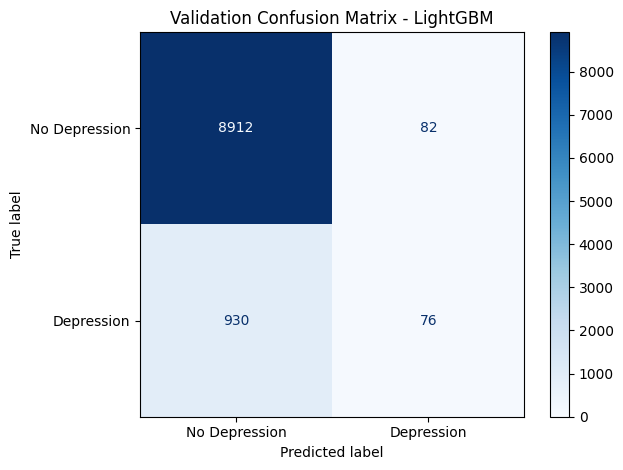

In [8]:
## BEST MODEL - VALIDATION DATASET EVALUATION

pred_val = best_model.predict(X_val[selected_features])

pred_val_proba = best_model.predict_proba(
    X_val[selected_features]
)[:, 1]

validation_metrics = {
    "Model": best_model_name,
    "Accuracy": accuracy_score(y_val, pred_val),
    "Precision": precision_score(y_val, pred_val, pos_label=1, zero_division=0),
    "Recall": recall_score(y_val, pred_val, pos_label=1, zero_division=0),
    "F1": f1_score(y_val, pred_val, pos_label=1, zero_division=0),
    "AUC": roc_auc_score(y_val, pred_val_proba),
    "Specificity": specificity_score(y_val, pred_val)
}

validation_best_model_df = pd.DataFrame([validation_metrics])

print("BEST MODEL PERFORMANCE ON VALIDATION DATASET")
display(validation_best_model_df.round(4))

validation_best_model_df.to_csv(
    "Best_Model_Validation_Performance.csv",
    index=False
)

"""## CONFUSION MATRIX OF THE BEST MODEL"""

from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

cm = confusion_matrix(y_val, pred_val, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Depression", "Depression"]
)

disp.plot(
    values_format="d",
    cmap="Blues",
    colorbar=True,
    im_kw={"vmin": 0, "vmax": cm.max()}
)

plt.title(f"Validation Confusion Matrix - {best_model_name}")
plt.tight_layout()

plt.savefig(
    "Best_Model_Validation_Confusion_Matrix.png",
    dpi=300
)

plt.show()

Best Performing Model: LightGBM
Number of SHAP observations: 1000
Using TreeExplainer


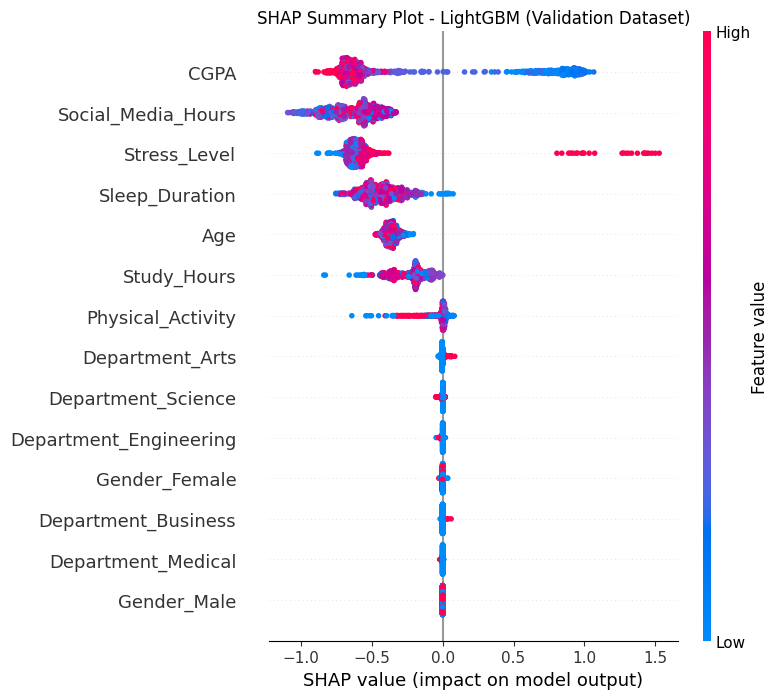

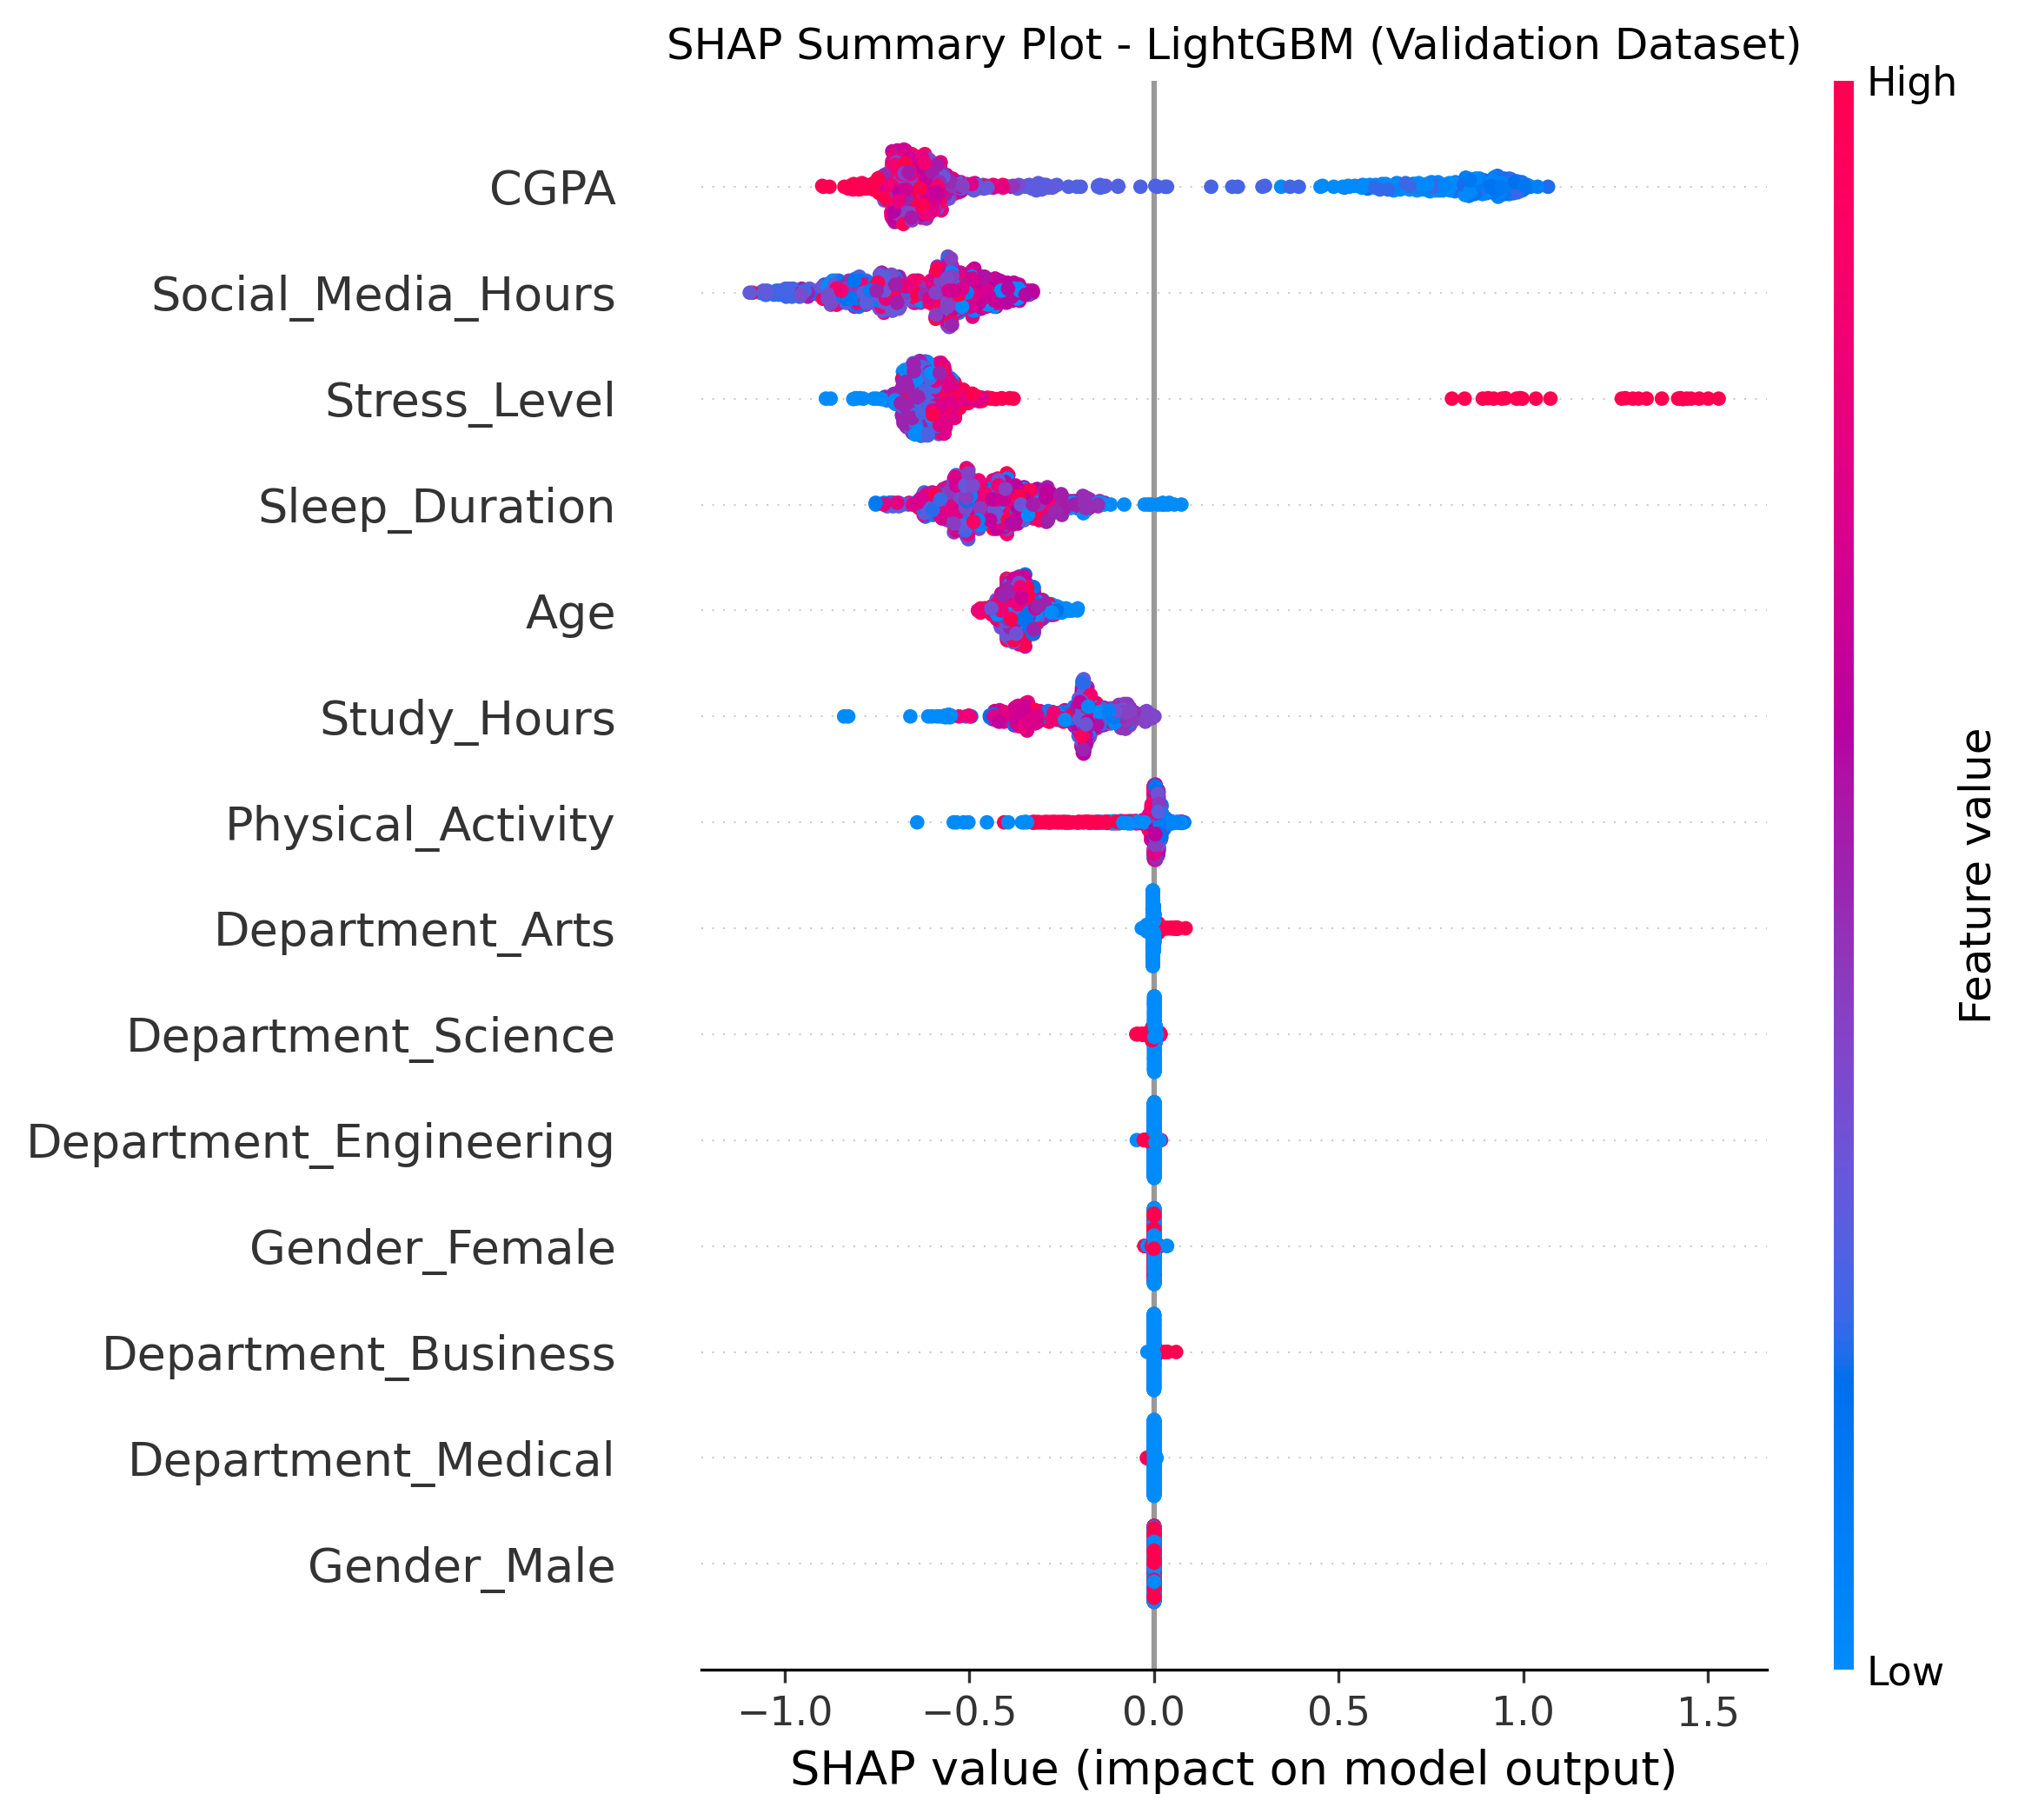

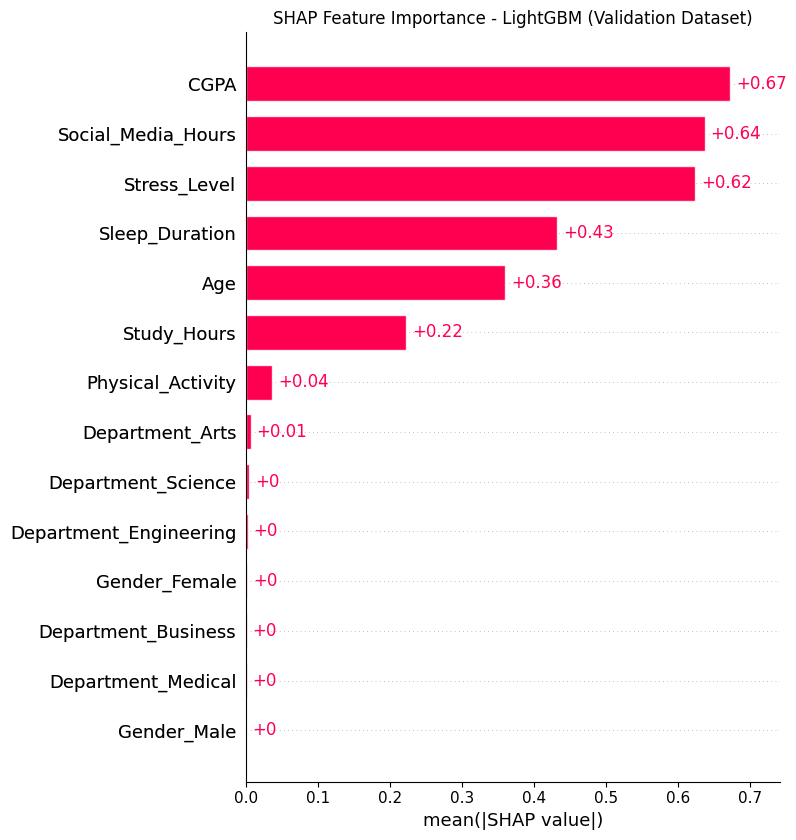

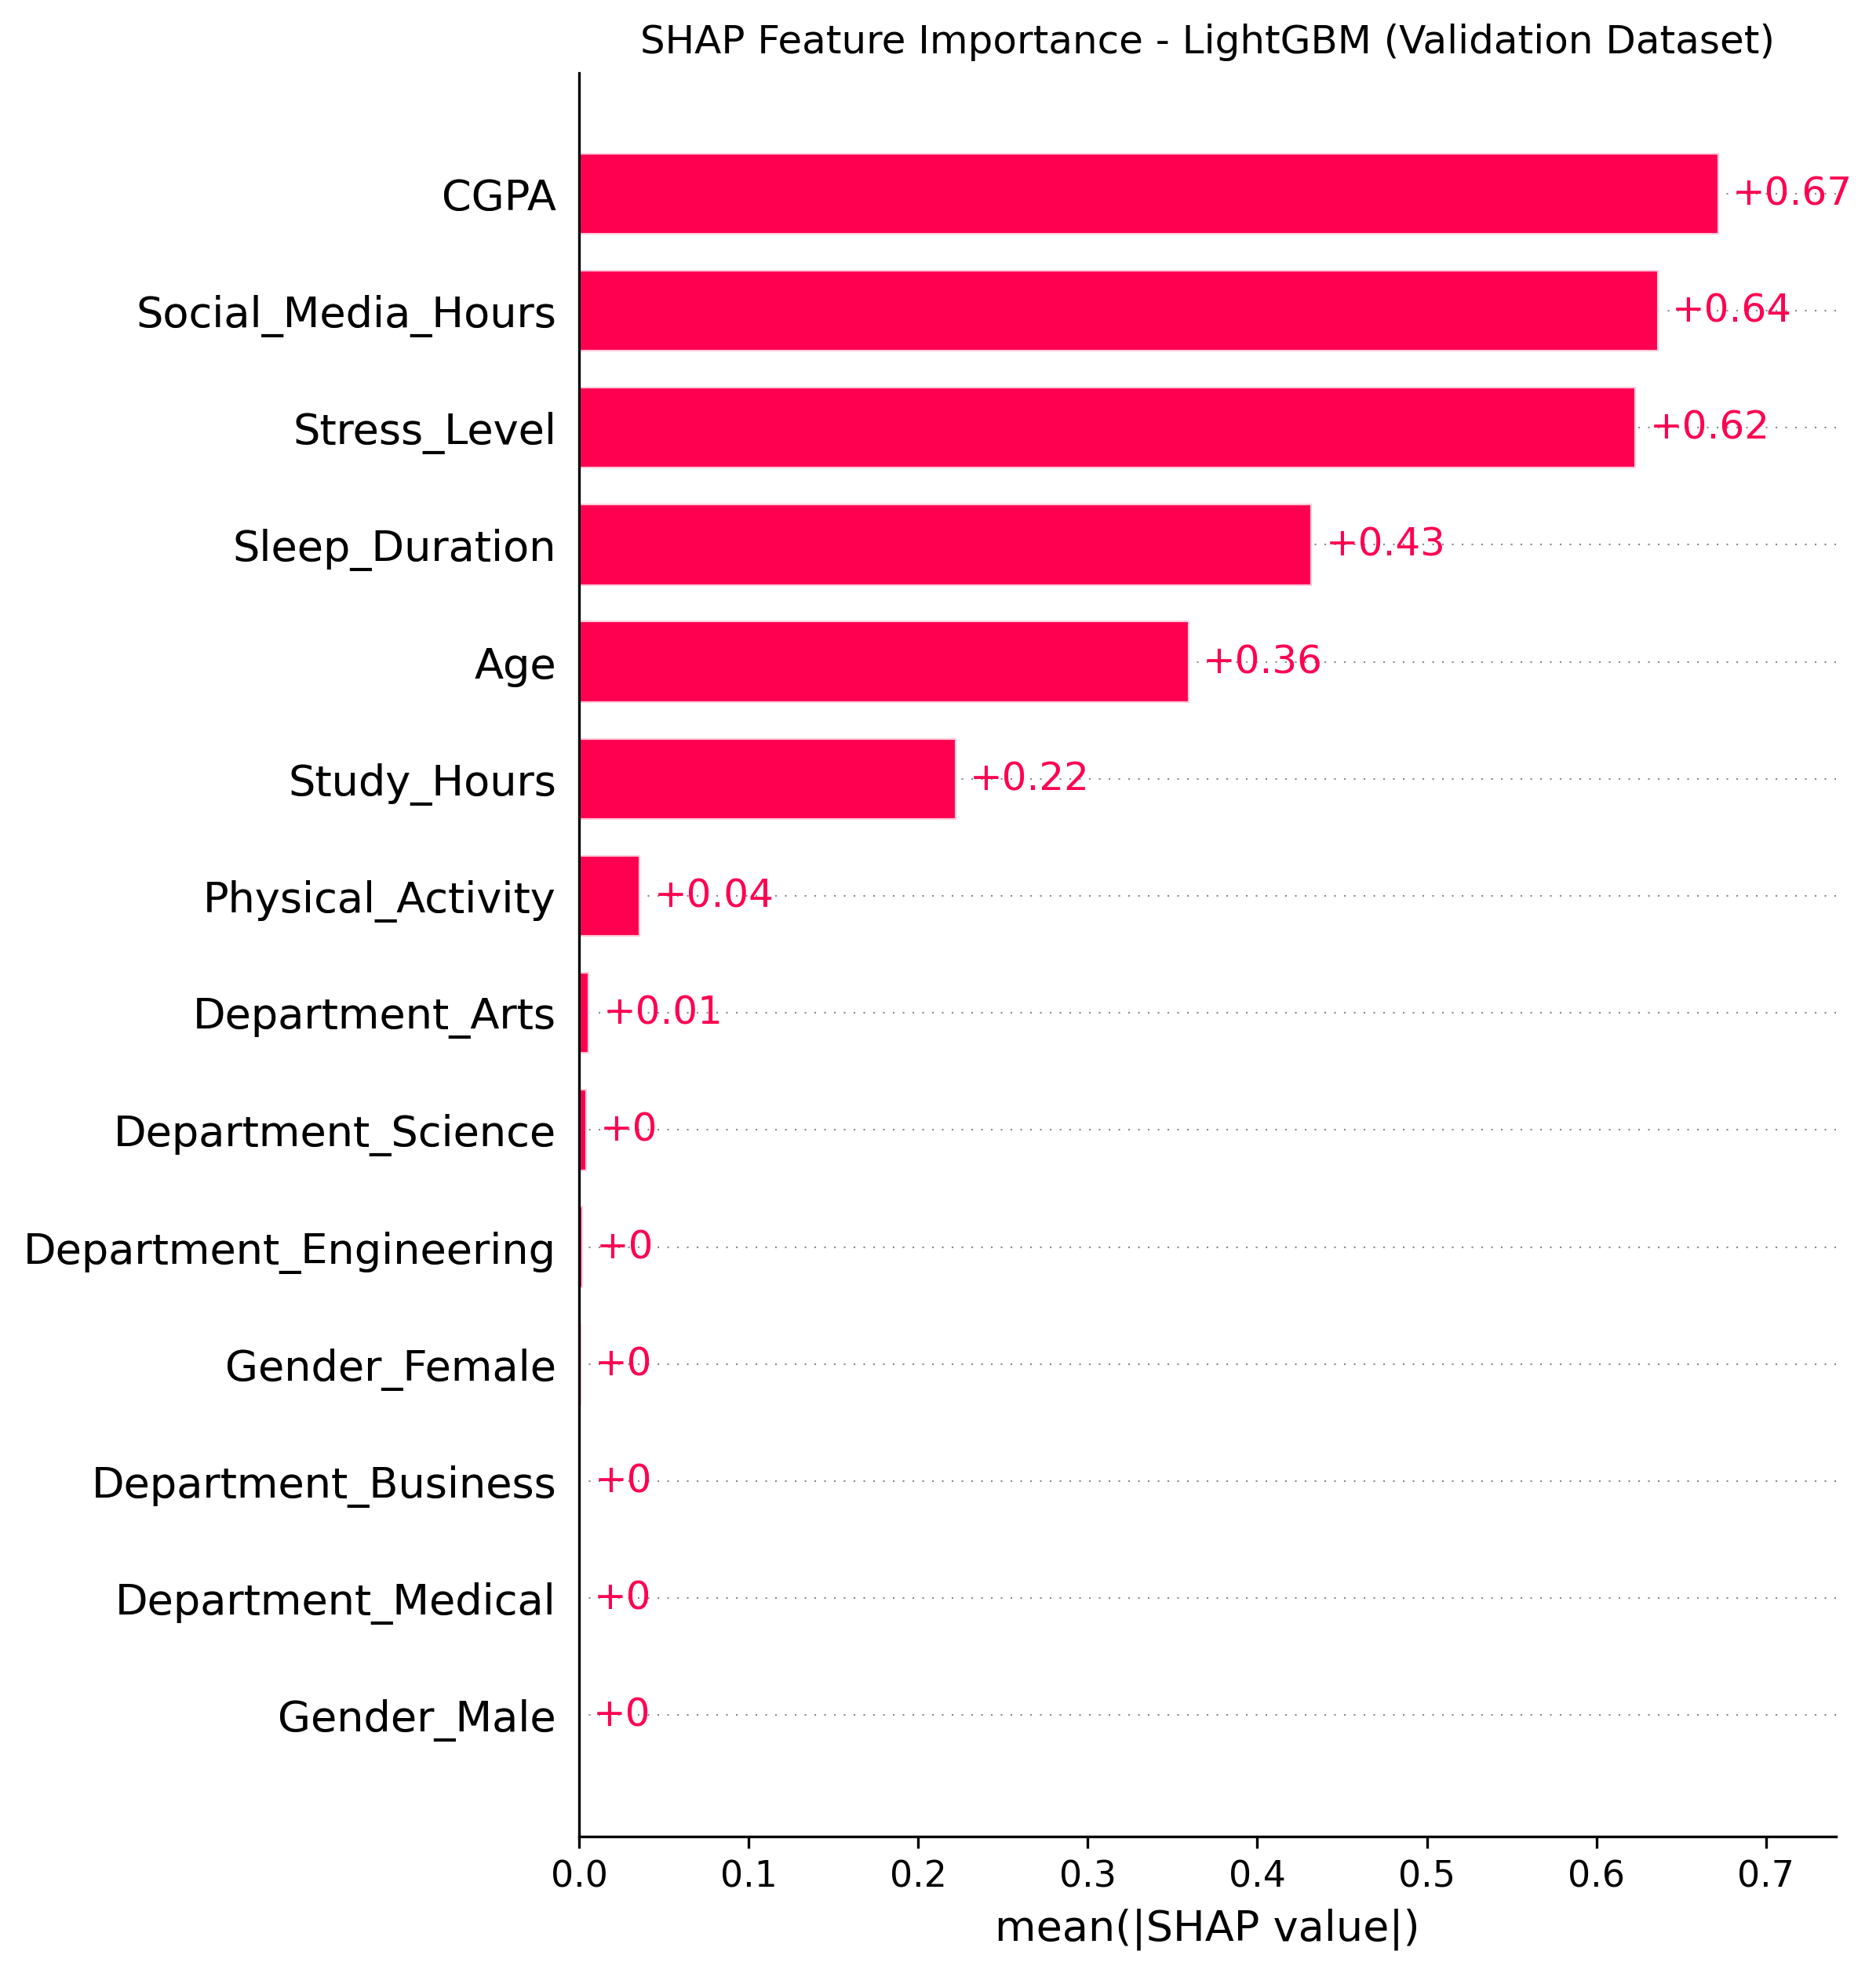


TOP 20 SHAP FEATURES


,Feature,Mean_Absolute_SHAP
0,CGPA,0.672336
1,Social_Media_Hours,0.636700
2,Stress_Level,0.623496
3,Sleep_Duration,0.432285
4,Age,0.359786
5,Study_Hours,0.222369
6,Physical_Activity,0.036118
7,Department_Arts,0.006160
8,Department_Science,0.004620
9,Department_Engineering,0.002114



All SHAP outputs saved successfully in SHAP_Outputs/


In [9]:
"""## SHAP ANALYSIS"""

## EXPLAINABLE AI - SHAP FOR BEST TESTING MODEL
## SHAP VALUES USING VALIDATION DATASET

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import display, Image

np.random.seed(42)

# 1. Identify best model using combined Testing F1 and AUC ranking
best_model_name = test_comparison.iloc[0]["Model"]

print("Best Performing Model:", best_model_name)

# 2. Retrieve the already-trained best model
best_pipeline = fitted_models[best_model_name]
trained_model = best_pipeline.named_steps["model"]

# 3. Select up to 1000 validation observations
X_shap = X_val[selected_features].sample(
    n=min(1000, len(X_val)),
    random_state=42
)

print("Number of SHAP observations:", len(X_shap))

# 4. Select background observations from training data
X_background = X_train[selected_features].sample(
    n=min(100, len(X_train)),
    random_state=42
)

# 5. Create output folder
os.makedirs("SHAP_Outputs", exist_ok=True)

# 6. Select appropriate SHAP explainer
model_type = type(trained_model).__name__.lower()

if any(name in model_type for name in
       ["randomforest", "xgb", "lgbm", "catboost", "gradientboosting"]):

    print("Using TreeExplainer")
    explainer = shap.TreeExplainer(trained_model)

    try:
        shap_values = explainer(
            X_shap,
            check_additivity=False
        )
    except TypeError:
        shap_values = explainer(X_shap)

elif "logisticregression" in model_type:

    print("Using LinearExplainer")
    explainer = shap.LinearExplainer(
        trained_model,
        X_background
    )
    shap_values = explainer(X_shap)

else:

    print("Using Permutation Explainer")
    explainer = shap.Explainer(
        trained_model.predict_proba,
        X_background,
        algorithm="permutation"
    )

    shap_values = explainer(
        X_shap,
        max_evals=2 * len(selected_features) + 1
    )

# 7. Extract positive-class SHAP values (Depression = 1)
if isinstance(shap_values, list):
    values = shap_values[1]
    base_values = explainer.expected_value
    if np.ndim(base_values) > 0:
        base_values = base_values[1]

else:
    values = shap_values.values
    base_values = shap_values.base_values

    if values.ndim == 3:
        values = values[:, :, 1]

        if np.ndim(base_values) == 2:
            base_values = base_values[:, 1]

# Create a consistent SHAP Explanation object
shap_values_positive = shap.Explanation(
    values=values,
    base_values=base_values,
    data=X_shap.to_numpy(),
    feature_names=list(X_shap.columns)
)

# 8. SHAP Summary Plot
plt.figure(figsize=(12, 8))

shap.plots.beeswarm(
    shap_values_positive,
    max_display=20,
    show=False
)

plt.title(
    f"SHAP Summary Plot - {best_model_name} (Validation Dataset)"
)

plt.tight_layout()

summary_path = "SHAP_Outputs/SHAP_Validation_Summary.png"

plt.savefig(
    summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Display saved image explicitly
display(Image(filename=summary_path))


# 9. SHAP Feature Importance Plot
plt.figure(figsize=(12, 8))

shap.plots.bar(
    shap_values_positive,
    max_display=20,
    show=False
)

plt.title(
    f"SHAP Feature Importance - {best_model_name} (Validation Dataset)"
)

plt.tight_layout()

importance_path = "SHAP_Outputs/SHAP_Validation_Feature_Importance.png"

plt.savefig(
    importance_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Display saved image explicitly
display(Image(filename=importance_path))


# 10. Save SHAP values as CSV
shap_values_df = pd.DataFrame(
    shap_values_positive.values,
    columns=X_shap.columns,
    index=X_shap.index
)

shap_values_df.to_csv(
    "SHAP_Outputs/SHAP_Validation_Values.csv"
)


# 11. Save mean absolute SHAP feature importance
feature_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": np.abs(
        shap_values_positive.values
    ).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

feature_importance.to_csv(
    "SHAP_Outputs/SHAP_Feature_Importance.csv",
    index=False
)

print("\nTOP 20 SHAP FEATURES")
display(feature_importance.head(20))

print("\nAll SHAP outputs saved successfully in SHAP_Outputs/")

## DEEP LEARNING MODELS

In [10]:
# -*- coding: utf-8 -*-
"""Deep Learning Algorithms .ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1R1AJcaW-iSxg7nARwUvZsaYw8Tzr-Hd2

Proposed research framework

1. 100K Student Depessin Dataset
2. Data Split
3. SMOTE on Training data
4. Data preprocessing and quality checks- missing values, duplicates, encoding, outliers, scaling
5. Statistical analysis: t-test
Feature selection: RFE.
6. Deep Learning - MLP and GLNet with Mamba Layers
7. Model evaluation - Stratified Cross validation, accuracy, precision, Recall. F1 score, auc, specificity
8. Explanaible AI - SHAP
"""

!pip install imbalanced-learn shap

import os
import random
import numpy as np
import torch

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Improve reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("All random seeds set to:", SEED)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, chi2_contingency

from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import shap

np.random.seed(42)

All random seeds set to: 42


In [11]:
## DATAPROCESSING AND QUALITY CHECKS

# Load the three separate datasets
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
validation = pd.read_csv("validation.csv")

# Separate features and target variable
X_train = train.drop("Depression", axis=1)
y_train = train["Depression"]

X_test = test.drop("Depression", axis=1)
y_test = test["Depression"]

X_val = validation.drop("Depression", axis=1)
y_val = validation["Depression"]


## DATAPROCESSING AND QUALITY CHECKS

# Missing values
print("Missing values in Training data:")
print(X_train.isnull().sum())

print("\nMissing values in Test data:")
print(X_test.isnull().sum())

print("\nMissing values in Validation data:")
print(X_val.isnull().sum())


# Duplicate rows
print("\nDuplicate rows in Training data:", X_train.duplicated().sum())
print("Duplicate rows in Test data:", X_test.duplicated().sum())
print("Duplicate rows in Validation data:", X_val.duplicated().sum())


# Remove duplicate rows from each dataset
duplicate_rows_train = X_train.index[X_train.duplicated()]
X_train = X_train.drop(index=duplicate_rows_train)
y_train = y_train.loc[X_train.index]

duplicate_rows_test = X_test.index[X_test.duplicated()]
X_test = X_test.drop(index=duplicate_rows_test)
y_test = y_test.loc[X_test.index]

duplicate_rows_val = X_val.index[X_val.duplicated()]
X_val = X_val.drop(index=duplicate_rows_val)
y_val = y_val.loc[X_val.index]


# Outlier check using the IQR method (numeric columns)
numeric_columns = X_train.select_dtypes(include=np.number).columns

for column in numeric_columns:
    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    print(column, "Outliers:",
          ((X_train[column] < lower_limit) |
           (X_train[column] > upper_limit)).sum())

print("\nData Processing and Quality Checks Completed")

# Separate numeric and categorical columns
numeric_columns = X_train.select_dtypes(include=np.number).columns
categorical_columns = X_train.select_dtypes(exclude=np.number).columns

# Missing value treatment: fit on training data only
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train[numeric_columns] = numeric_imputer.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = numeric_imputer.transform(X_test[numeric_columns])
X_val[numeric_columns] = numeric_imputer.transform(X_val[numeric_columns])

if len(categorical_columns) > 0:
    X_train[categorical_columns] = categorical_imputer.fit_transform(X_train[categorical_columns])
    X_test[categorical_columns] = categorical_imputer.transform(X_test[categorical_columns])
    X_val[categorical_columns] = categorical_imputer.transform(X_val[categorical_columns])

# Encoding categorical variables
X_train = pd.get_dummies(X_train, columns=categorical_columns)
X_test = pd.get_dummies(X_test, columns=categorical_columns)
X_val = pd.get_dummies(X_val, columns=categorical_columns)

# Make test and validation columns match training columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)

# Scaling: fit on training data only
sc = MinMaxScaler()
X_train = pd.DataFrame(sc.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(sc.transform(X_test), columns=X_test.columns, index=X_test.index)
X_val = pd.DataFrame(sc.transform(X_val), columns=X_val.columns, index=X_val.index)

print("Preprocessing completed")

Missing values in Training data:
Age                   0
Gender                0
Department            0
CGPA                  0
Sleep_Duration        0
Study_Hours           0
Social_Media_Hours    0
Physical_Activity     0
Stress_Level          0
dtype: int64

Missing values in Test data:
Age                   0
Gender                0
Department            0
CGPA                  0
Sleep_Duration        0
Study_Hours           0
Social_Media_Hours    0
Physical_Activity     0
Stress_Level          0
dtype: int64

Missing values in Validation data:
Age                   0
Gender                0
Department            0
CGPA                  0
Sleep_Duration        0
Study_Hours           0
Social_Media_Hours    0
Physical_Activity     0
Stress_Level          0
dtype: int64

Duplicate rows in Training data: 0
Duplicate rows in Test data: 0
Duplicate rows in Validation data: 0
Age Outliers: 0
CGPA Outliers: 0
Sleep_Duration Outliers: 259
Study_Hours Outliers: 286
Social_Media_Hours Out

In [12]:
## SMOTE ON TRAINING DATA

print("Class distribution before SMOTE:")
print(y_train.value_counts())

sm = SMOTE(random_state=42)
X_train_smote, y_train_smote = sm.fit_resample(X_train, y_train)

print("Class distribution after SMOTE:")
print(pd.Series(y_train_smote).value_counts())

## T-TEST

# t-test for numeric predictors against a binary target
t_test_results = []

for column in X_train.select_dtypes(include=np.number).columns:
    group_0 = X_train.loc[np.asarray(y_train) == 0, column]
    group_1 = X_train.loc[np.asarray(y_train) == 1, column]

    t_stat, p_value = ttest_ind(group_0, group_1, equal_var=False, nan_policy="omit")
    t_test_results.append([column, t_stat, p_value])

t_test_df = pd.DataFrame(t_test_results, columns=["Feature", "T-Statistic", "P-Value"])
t_test_df = t_test_df.sort_values("P-Value")
t_test_df

## FEATURE SELECTION - RFE

np.random.seed(42)

rfe_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)
rfe = RFE(estimator=rfe_model, n_features_to_select=min(15, X_train_smote.shape[1]))
rfe.fit(X_train_smote, y_train_smote)

selected_features = X_train_smote.columns[rfe.support_]
print("Selected Features:")
print(selected_features)

X_train_selected = X_train_smote[selected_features]
X_test_selected = X_test[selected_features]
X_val_selected = X_val[selected_features]


Class distribution before SMOTE:
Depression
False    62957
True      7043
Name: count, dtype: int64
Class distribution after SMOTE:
Depression
False    62957
True     62957
Name: count, dtype: int64
Selected Features:
Index(['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours',
       'Physical_Activity', 'Stress_Level', 'Gender_Female', 'Gender_Male',
       'Department_Arts', 'Department_Business', 'Department_Engineering',
       'Department_Medical', 'Department_Science'],
      dtype='object')


In [13]:
## MLP Classifier
def evaluate_model(y_true, probabilities):

    y_true = np.asarray(y_true).astype(int)

    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, predictions),

        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),

        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),

        "AUC": roc_auc_score(
            y_true, probabilities
        ),

        "Sensitivity": tp / (tp + fn) if tp + fn else 0,

        "Specificity": tn / (tn + fp) if tn + fp else 0
    }

SEED = 42

mlp_pipeline = ImbPipeline([

    ("smote", SMOTE(random_state=SEED)),

    ("rfe", RFE(
        LogisticRegression(max_iter=1000, random_state=SEED),
        n_features_to_select=min(
            15,
            X_train.shape[1]
        )
    )),

    ("model", MLPClassifier(
        max_iter=200,
        early_stopping=True,
        random_state=SEED
    ))
])

parameters = {

    "model__hidden_layer_sizes": [
        (32,),
        (64,),
        (100,)
    ],

    "model__alpha": [
        0.0001,
        0.001,
        0.01
    ],

    "model__learning_rate_init": [
        0.001,
        0.01
    ]
}

final_mlp = RandomizedSearchCV(
    mlp_pipeline,
    parameters,
    n_iter=6,
    cv=3,
    scoring="roc_auc",
    random_state=SEED,
    n_jobs=-1,
    refit=True
)

print("Training MLP...")

final_mlp.fit(
    X_train,
    y_train
)

print("Best MLP parameters:")
print(final_mlp.best_params_)

mlp_test_prob = final_mlp.predict_proba(
    X_test
)[:, 1]

mlp_test_metrics = evaluate_model(
    y_test,
    mlp_test_prob
)

print("MLP Testing Results:")
display(pd.DataFrame([mlp_test_metrics]).round(4))


Training MLP...
Best MLP parameters:
{'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': (32,), 'model__alpha': 0.0001}
MLP Testing Results:


,Accuracy,Precision,Recall,F1,AUC,Sensitivity,Specificity
0,0.7076,0.2004,0.6369,0.3048,0.695,0.6369,0.7156


In [14]:
## GLNet
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# Define the execution device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MambaLayer(nn.Module):

    def __init__(self, d_model, d_state=8):

        super().__init__()

        self.d_model = d_model
        self.d_state = d_state

        self.norm = nn.LayerNorm(d_model)

        self.in_proj = nn.Linear(
            d_model, d_model * 2
        )

        self.x_proj = nn.Linear(
            d_model, d_model + 2 * d_state
        )

        self.dt_proj = nn.Linear(
            d_model, d_model
        )

        self.A_log = nn.Parameter(
            torch.randn(d_model, d_state) * 0.1
        )

        self.D = nn.Parameter(
            torch.ones(d_model)
        )

        self.out_proj = nn.Linear(
            d_model, d_model
        )

    def forward(self, x):

        residual = x
        x = self.norm(x)

        xz = self.in_proj(x)

        x_input, z = xz.chunk(2, dim=-1)

        projected = self.x_proj(x_input)

        dt_input, B, C = torch.split(
            projected,
            [
                self.d_model,
                self.d_state,
                self.d_state
            ],
            dim=-1
        )

        dt = F.softplus(
            self.dt_proj(dt_input)
        ) + 1e-4

        A = -torch.exp(self.A_log)

        batch_size, seq_len, _ = x_input.shape

        state = torch.zeros(
            batch_size,
            self.d_model,
            self.d_state,
            device=x.device,
            dtype=x.dtype
        )

        outputs = []

        for t in range(seq_len):

            dt_t = dt[:, t, :]
            B_t = B[:, t, :]
            C_t = C[:, t, :]
            x_t = x_input[:, t, :]

            dA = torch.exp(
                dt_t.unsqueeze(-1) *
                A.unsqueeze(0)
            )

            dB = (
                dt_t.unsqueeze(-1)
                * B_t.unsqueeze(1)
                * x_t.unsqueeze(-1)
            )

            state = dA * state + dB

            y = torch.sum(
                state * C_t.unsqueeze(1),
                dim=-1
            )

            y = y + self.D * x_t

            outputs.append(y)

        output = torch.stack(
            outputs,
            dim=1
        )

        output = output * F.silu(z)

        output = self.out_proj(output)

        return output + residual


class GLNetMamba(nn.Module):

    def __init__(
        self,
        n_features,
        d_model=32,
        d_state=8,
        n_layers=2
    ):

        super().__init__()

        self.feature_projection = nn.Linear(
            1, d_model
        )

        self.feature_embedding = nn.Parameter(
            torch.randn(1, n_features, d_model) * 0.02
        )

        self.gate_linear = nn.Linear(
            d_model, d_model
        )

        self.value_linear = nn.Linear(
            d_model, d_model
        )

        self.mamba_layers = nn.ModuleList([
            MambaLayer(d_model, d_state)
            for _ in range(n_layers)
        ])

        self.norm = nn.LayerNorm(d_model)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):

        x = x.unsqueeze(-1)

        x = self.feature_projection(x)

        x = x + self.feature_embedding

        gate = torch.sigmoid(
            self.gate_linear(x)
        )

        value = F.silu(
            self.value_linear(x)
        )

        x = gate * value + x

        for layer in self.mamba_layers:
            x = layer(x)

        x = self.norm(x)

        x = x.mean(dim=1)

        return self.classifier(x)

# Apply SMOTE to training data only

smote = SMOTE(random_state=SEED)

X_resampled, y_resampled = smote.fit_resample(
    X_train,
    y_train
)

# Feature selection using RFE

selector = RFE(
    LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ),
    n_features_to_select=min(
        15,
        X_train.shape[1]
    )
)

X_resampled = selector.fit_transform(
    X_resampled,
    y_resampled
)

# Transform test and validation datasets

X_test_selected = selector.transform(
    X_test
)

X_val_selected = selector.transform(
    X_val
)

# Keep original feature names
selected_features_glnet = (
    X_train.columns[selector.support_].tolist()
)

print("Selected GLNet features:", len(selected_features_glnet))

def train_glnet(
    X_data,
    y_data,
    epochs=20,
    batch_size=128
):

    X_tensor = torch.tensor(
        np.asarray(X_data),
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        np.asarray(y_data),
        dtype=torch.float32
    ).reshape(-1, 1)

    dataset = TensorDataset(
        X_tensor,
        y_tensor
    )

    # Reproducible DataLoader shuffling
    generator = torch.Generator()
    generator.manual_seed(SEED)

    loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
    )

    model = GLNetMamba(
        n_features=X_data.shape[1],
        d_model=32,
        d_state=8,
        n_layers=2
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(
                outputs,
                y_batch
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(loader)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {avg_loss:.4f}"
        )

    return model


def predict_glnet(model, X_data):

    model.eval()

    X_tensor = torch.tensor(
        np.asarray(X_data),
        dtype=torch.float32
    ).to(device)

    with torch.no_grad():

        logits = model(X_tensor)

        probabilities = torch.sigmoid(
            logits
        ).cpu().numpy().flatten()

    return probabilities


print("Training GLNet-Mamba...")

final_glnet = train_glnet(
    X_resampled,
    y_resampled,
    epochs=20
)

glnet_test_prob = predict_glnet(
    final_glnet,
    X_test_selected
)

glnet_test_metrics = evaluate_model(
    y_test,
    glnet_test_prob
)

print("GLNet-Mamba Testing Results:")

display(
    pd.DataFrame([glnet_test_metrics]).round(4)
)

# Define output directory
OUTPUT_DIR = "."

# Collect testing results
test_results = [

    {
        "Model": "MLP",
        **mlp_test_metrics
    },

    {
        "Model": "GLNet-Mamba",
        **glnet_test_metrics
    }

]

test_comparison = pd.DataFrame(test_results)

Selected GLNet features: 14
Training GLNet-Mamba...
Epoch [1/20] Loss: 0.6442
Epoch [2/20] Loss: 0.6160
Epoch [3/20] Loss: 0.6116
Epoch [4/20] Loss: 0.5936
Epoch [5/20] Loss: 0.5894
Epoch [6/20] Loss: 0.5873
Epoch [7/20] Loss: 0.5852
Epoch [8/20] Loss: 0.5834
Epoch [9/20] Loss: 0.5769
Epoch [10/20] Loss: 0.5687
Epoch [11/20] Loss: 0.5690
Epoch [12/20] Loss: 0.5793
Epoch [13/20] Loss: 0.5758
Epoch [14/20] Loss: 0.5655
Epoch [15/20] Loss: 0.5513
Epoch [16/20] Loss: 0.5353
Epoch [17/20] Loss: 0.5356
Epoch [18/20] Loss: 0.5351
Epoch [19/20] Loss: 0.5488
Epoch [20/20] Loss: 0.5314
GLNet-Mamba Testing Results:


,Accuracy,Precision,Recall,F1,AUC,Sensitivity,Specificity
0,0.7446,0.2041,0.5301,0.2947,0.6801,0.5301,0.7687


TESTING DATASET - MODEL COMPARISON
Ranking based on F1-Score and Recall


,Model,Accuracy,Precision,Recall,F1,AUC,Sensitivity,Specificity,F1_Rank,Recall_Rank,Average_Rank,Final_Rank
0,MLP,0.7076,0.2004,0.6369,0.3048,0.6950,0.6369,0.7156,1.0,1.0,0.6667,1
1,GLNet-Mamba,0.7446,0.2041,0.5301,0.2947,0.6801,0.5301,0.7687,2.0,2.0,1.3333,2


Comparison table saved successfully.


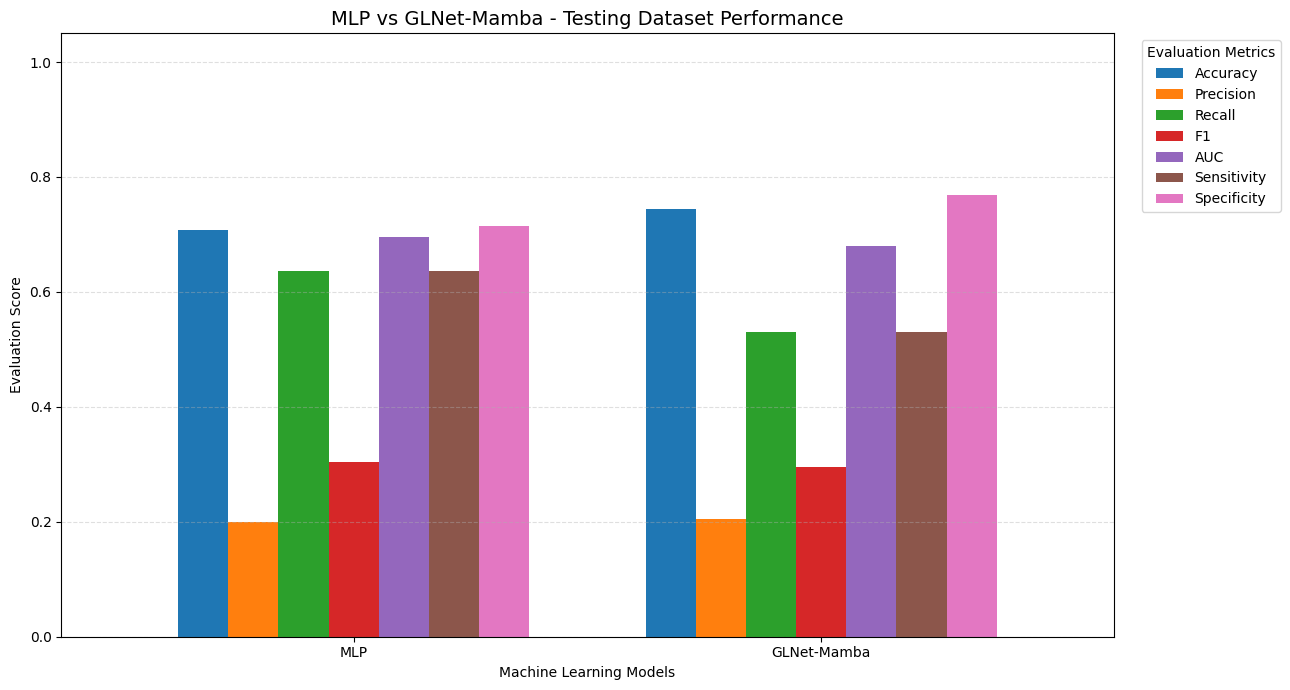

In [16]:
# ==========================================
# RANK BASED ON F1 AND RECALL
# ==========================================

# Rank F1 (highest receives rank 1)
test_comparison["F1_Rank"] = (
    test_comparison["F1"]
    .rank(ascending=False, method="min")
)

# Rank Recall (highest receives rank 1)
test_comparison["Recall_Rank"] = (
    test_comparison["Recall"]
    .rank(ascending=False, method="min")
)

# Calculate average rank across all three metrics
test_comparison["Average_Rank"] = (
    test_comparison["F1_Rank"]
    + test_comparison["Recall_Rank"]
) / 3

# Sort by average rank
test_comparison = test_comparison.sort_values(
    by=["Average_Rank", "F1", "Recall"],
    ascending=[True, False, False]
).reset_index(drop=True)

# Add final ranking
test_comparison["Final_Rank"] = (
    range(1, len(test_comparison) + 1)
)

# ==========================================
# DISPLAY COMPARISON TABLE
# ==========================================

print("TESTING DATASET - MODEL COMPARISON")
print("Ranking based on F1-Score and Recall")

display(test_comparison.round(4))

# ==========================================
# SAVE TABLE
# ==========================================

test_comparison.to_csv(
    f"{OUTPUT_DIR}/Testing_Model_Comparison.csv",
    index=False
)

test_comparison.to_excel(
    f"{OUTPUT_DIR}/Testing_Model_Comparison.xlsx",
    index=False
)

print("Comparison table saved successfully.")

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "AUC",
    "Sensitivity",
    "Specificity"
]

plot_data = test_comparison.set_index("Model")[metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.75
)

plt.title(
    "MLP vs GLNet-Mamba - Testing Dataset Performance",
    fontsize=14
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Evaluation Score")

plt.ylim(0, 1.05)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Testing_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

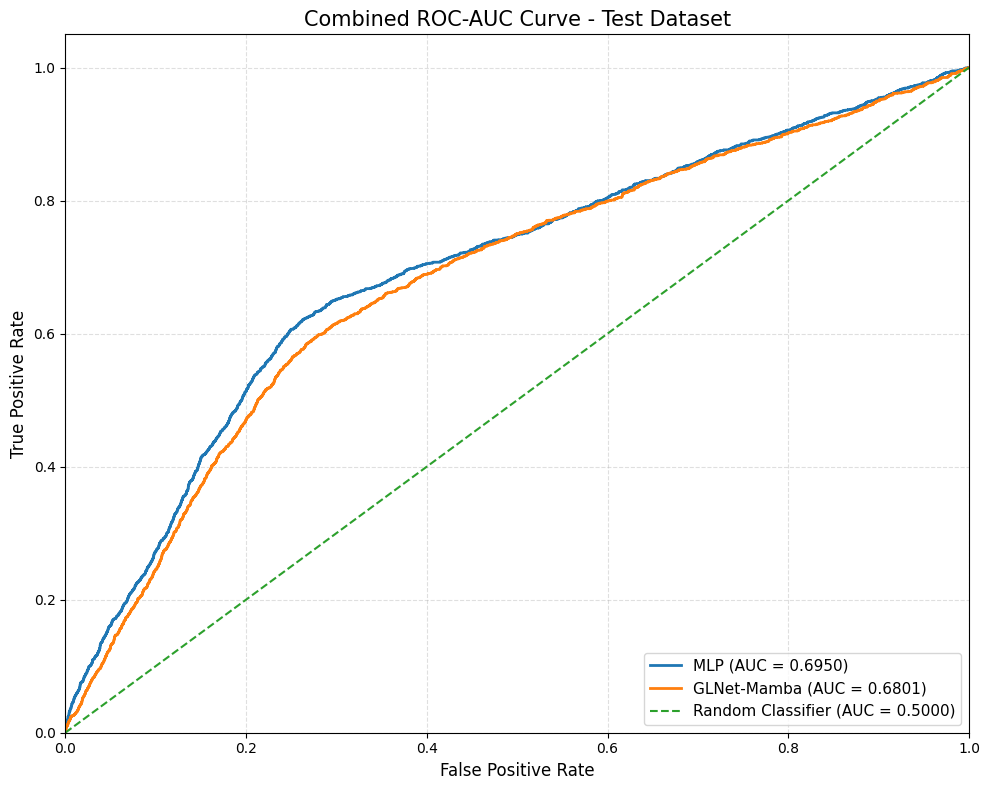

,Model,Test AUC,Rank
0,MLP,0.6950,1
1,GLNet-Mamba,0.6801,2


ROC-AUC curve and comparison table saved successfully.


In [17]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import pandas as pd
import os

# Output directory
OUTPUT_DIR = "."
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Predicted probabilities from both models
model_probabilities = {
    "MLP": mlp_test_prob,
    "GLNet-Mamba": glnet_test_prob
}

# Create combined ROC curve
plt.figure(figsize=(10, 8))

roc_results = []

for model_name, probabilities in model_probabilities.items():

    # Calculate ROC values
    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    # Calculate AUC
    auc_value = roc_auc_score(
        y_test,
        probabilities
    )

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )

    roc_results.append({
        "Model": model_name,
        "Test AUC": auc_value
    })

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.5000)"
)

# Chart formatting
plt.title(
    "Combined ROC-AUC Curve - Test Dataset",
    fontsize=15
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(
    loc="lower right",
    fontsize=11
)

plt.grid(
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

# Save figure
plt.savefig(
    f"{OUTPUT_DIR}/Combined_ROC_AUC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Display AUC comparison table
roc_results_df = pd.DataFrame(roc_results)

roc_results_df = roc_results_df.sort_values(
    by="Test AUC",
    ascending=False
).reset_index(drop=True)

roc_results_df["Rank"] = range(
    1, len(roc_results_df) + 1
)

display(roc_results_df.round(4))

# Save results
roc_results_df.to_csv(
    f"{OUTPUT_DIR}/Combined_ROC_AUC_Results.csv",
    index=False
)

roc_results_df.to_excel(
    f"{OUTPUT_DIR}/Combined_ROC_AUC_Results.xlsx",
    index=False
)

print("ROC-AUC curve and comparison table saved successfully.")

--------------------------------------
BEST MODEL BASED ON TESTING DATA
--------------------------------------
Selected Model: MLP
Testing F1: 0.3048
Testing AUC: 0.695
Average Rank: 0.6666666666666666
--------------------------------------
BEST MODEL - VALIDATION PERFORMANCE
--------------------------------------


,Selected Model,Accuracy,Precision,Recall,F1,AUC,Sensitivity,Specificity
0,MLP,0.7116,0.2062,0.6551,0.3137,0.7069,0.6551,0.7179


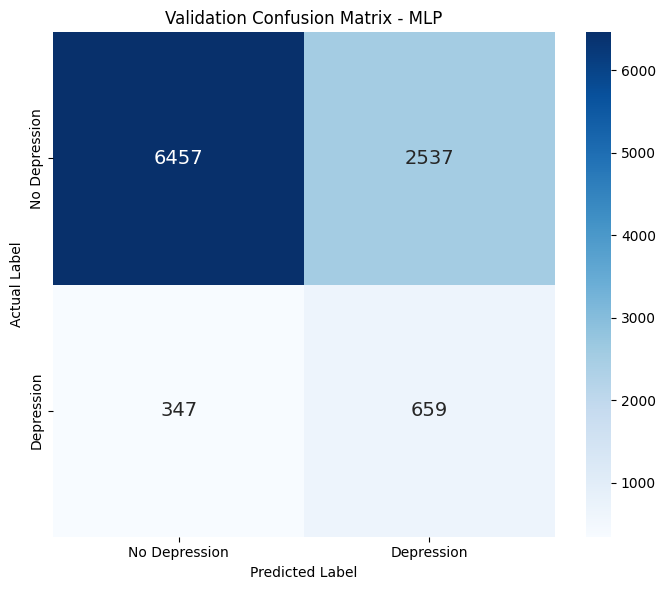

Confusion Matrix Values:
[[6457 2537]
 [ 347  659]]


In [18]:

best_model_name = test_comparison.iloc[0]["Model"]

print("--------------------------------------")
print("BEST MODEL BASED ON TESTING DATA")
print("--------------------------------------")

print("Selected Model:", best_model_name)

print(
    "Testing F1:",
    round(test_comparison.iloc[0]["F1"], 4)
)

print(
    "Testing AUC:",
    round(test_comparison.iloc[0]["AUC"], 4)
)

print(
    "Average Rank:",
    test_comparison.iloc[0]["Average_Rank"]
)

# Get predictions from the selected model

if best_model_name == "MLP":

    val_probabilities = final_mlp.predict_proba(
        X_val
    )[:, 1]

elif best_model_name == "GLNet-Mamba":

    val_probabilities = predict_glnet(
        final_glnet,
        X_val_selected
    )


# Calculate validation metrics

validation_metrics = evaluate_model(
    y_val,
    val_probabilities
)

validation_results = pd.DataFrame([{
    "Selected Model": best_model_name,
    **validation_metrics
}])

print("--------------------------------------")
print("BEST MODEL - VALIDATION PERFORMANCE")
print("--------------------------------------")

display(validation_results.round(4))

# Save validation table

validation_results.to_csv(
    f"{OUTPUT_DIR}/Best_Model_Validation_Metrics.csv",
    index=False
)

validation_results.to_excel(
    f"{OUTPUT_DIR}/Best_Model_Validation_Metrics.xlsx",
    index=False
)

# Convert validation probabilities to predictions

val_predictions = (
    val_probabilities >= 0.5
).astype(int)

cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Depression", "Depression"],
    yticklabels=["No Depression", "Depression"],
    annot_kws={"size": 14}
)

plt.title(
    f"Validation Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Best_Model_Validation_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Confusion Matrix Values:")
print(cm)


SHAP analysis for MLP


PermutationExplainer explainer: 1001it [00:13, 20.76it/s]                           


Number of SHAP observations: 1000


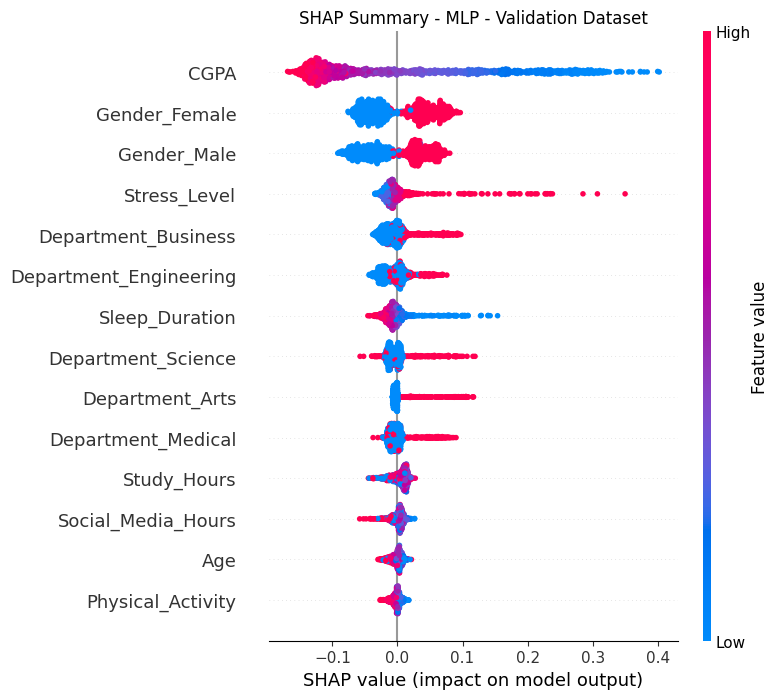

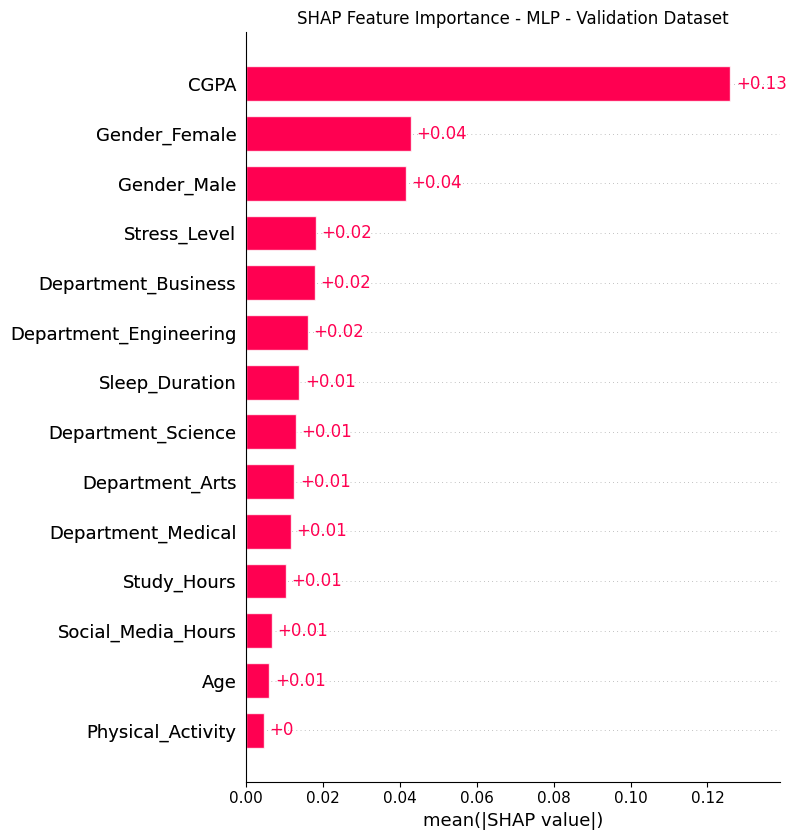

TOP 20 SHAP FEATURES


,Feature,Mean_Absolute_SHAP
0,CGPA,0.12597
1,Gender_Female,0.04283
2,Gender_Male,0.04149
3,Stress_Level,0.01813
4,Department_Business,0.01785
5,Department_Engineering,0.01606
6,Sleep_Duration,0.01388
7,Department_Science,0.01297
8,Department_Arts,0.01249
9,Department_Medical,0.01169


In [20]:
# Select up to 1000 validation observations

N_SHAP = min(1000, len(X_val))

if best_model_name == "MLP":

    print("SHAP analysis for MLP")

    # Use all original processed features.
    # The fitted pipeline applies its own RFE transformation.

    X_shap_df = X_val.sample(
        n=N_SHAP,
        random_state=SEED
    )

    X_background_df = X_train.sample(
        n=min(50, len(X_train)),
        random_state=SEED
    )

    def mlp_predict_function(data):

        data_df = pd.DataFrame(
            data,
            columns=X_train.columns
        )

        return final_mlp.predict_proba(data_df)[:, 1]

    masker = shap.maskers.Independent(
        X_background_df
    )

    explainer = shap.Explainer(
        mlp_predict_function,
        masker,
        algorithm="permutation"
    )

    shap_values = explainer(
        X_shap_df,
        max_evals=2 * X_shap_df.shape[1] + 1
    )

    X_shap_display = X_shap_df

elif best_model_name == "GLNet-Mamba":

    print("SHAP analysis for GLNet-Mamba")

    X_shap_df = pd.DataFrame(
        X_val_selected[:N_SHAP],
        columns=selected_features_glnet
    )

    background_array = X_train.sample(
        n=min(50, len(X_train)),
        random_state=SEED
    )

    background_selected = selector.transform(
        background_array
    )

    background_tensor = torch.tensor(
        background_selected,
        dtype=torch.float32
    ).to(device)

    X_shap_tensor = torch.tensor(
        X_shap_df.to_numpy(),
        dtype=torch.float32
    ).to(device)

    final_glnet.eval()

    explainer = shap.GradientExplainer(
        final_glnet,
        background_tensor
    )

    shap_raw = explainer.shap_values(
        X_shap_tensor
    )

    # Convert SHAP output to a two-dimensional array

    if isinstance(shap_raw, list):
        shap_raw = shap_raw[0]

    shap_raw = np.asarray(shap_raw)

    if shap_raw.ndim == 3 and shap_raw.shape[-1] == 1:
        shap_raw = shap_raw[:, :, 0]

    elif shap_raw.ndim == 3 and shap_raw.shape[1] == 1:
        shap_raw = shap_raw[:, 0, :]

    shap_values = shap.Explanation(
        values=shap_raw,
        data=X_shap_df.to_numpy(),
        feature_names=selected_features_glnet
    )

    X_shap_display = X_shap_df


print(
    "Number of SHAP observations:",
    len(X_shap_display)
)

# SHAP Summary Plot

plt.figure(figsize=(12, 8))

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    f"SHAP Summary - {best_model_name} - Validation Dataset"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/SHAP_Validation_Summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# SHAP Feature Importance Plot

plt.figure(figsize=(12, 8))

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    f"SHAP Feature Importance - {best_model_name} - Validation Dataset"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/SHAP_Validation_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Extract SHAP values

shap_array = np.asarray(shap_values.values)

shap_df = pd.DataFrame(
    shap_array,
    columns=X_shap_display.columns,
    index=X_shap_display.index
)

# Save individual SHAP values

shap_df.to_csv(
    f"{OUTPUT_DIR}/SHAP_Validation_Values.csv"
)

# Calculate mean absolute SHAP values

importance_df = pd.DataFrame({

    "Feature": X_shap_display.columns,

    "Mean_Absolute_SHAP": np.abs(
        shap_array
    ).mean(axis=0)

})

importance_df = importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Save importance table

importance_df.to_csv(
    f"{OUTPUT_DIR}/SHAP_Feature_Importance.csv",
    index=False
)

importance_df.to_excel(
    f"{OUTPUT_DIR}/SHAP_Feature_Importance.xlsx",
    index=False
)

print("TOP 20 SHAP FEATURES")

display(
    importance_df.head(20).round(5))

In [21]:
# ==========================================
# MODEL COMPARISON WITH TEST SET
# Traditional Machine Learning Algorithms
# ==========================================

# Extract test columns from the already computed model_results_df
test_columns = [
    "Model",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test AUC",
    "Test Specificity"
]

test_comparison_df = model_results_df[test_columns].copy()

# Rename columns
test_comparison_df = test_comparison_df.rename(columns={
    "Test Accuracy": "Accuracy",
    "Test Precision": "Precision",
    "Test Recall": "Recall",
    "Test F1": "F1-Score",
    "Test AUC": "ROC-AUC",
    "Test Specificity": "Specificity"
})

# Sort by F1-Score and Recall (with matching lengths for both lists)
test_comparison_df = test_comparison_df.sort_values(
    by=["F1-Score", "ROC-AUC"],
    ascending=[False, False]
).reset_index(drop=True)

# Round values
test_comparison_df = test_comparison_df.round(4)

# Display table
print("TRADITIONAL ML - TEST SET MODEL COMPARISON")
display(test_comparison_df)

# Save table
test_comparison_df.to_csv(
    "ML_Test_Set_Model_Comparison.csv",
    index=False
)

test_comparison_df.to_excel(
    "ML_Test_Set_Model_Comparison.xlsx",
    index=False
)

print("Test-set model comparison table saved successfully.")

TRADITIONAL ML - TEST SET MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Specificity
0,LightGBM,0.8974,0.8570,0.8974,0.8616,0.6954,0.9907
1,XGBoost,0.8972,0.8542,0.8972,0.8597,0.6959,0.9917
2,CatBoost,0.8984,0.8550,0.8984,0.8572,0.6983,0.9952
3,Random Forest,0.8682,0.8415,0.8682,0.8532,0.6859,0.9490
4,KNN,0.6806,0.8392,0.6806,0.7405,0.5945,0.7087
5,Gaussian Naive Bayes,0.6341,0.8639,0.6341,0.7070,0.6797,0.6320
6,SVM,0.6222,0.8646,0.6222,0.6974,0.6812,0.6172
7,Logistic Regression,0.6221,0.8645,0.6221,0.6973,0.6814,0.6171


Test-set model comparison table saved successfully.


In [22]:
# Identify the best traditional ML model
best_traditional_name = test_comparison_df.iloc[0]["Model"]

print("BEST TRADITIONAL ML MODEL:", best_traditional_name)
print("Best F1-Score:", test_comparison_df.iloc[0]["F1-Score"])
print("Best ROC-AUC:", test_comparison_df.iloc[0]["ROC-AUC"])

BEST TRADITIONAL ML MODEL: LightGBM
Best F1-Score: 0.8616
Best ROC-AUC: 0.6954


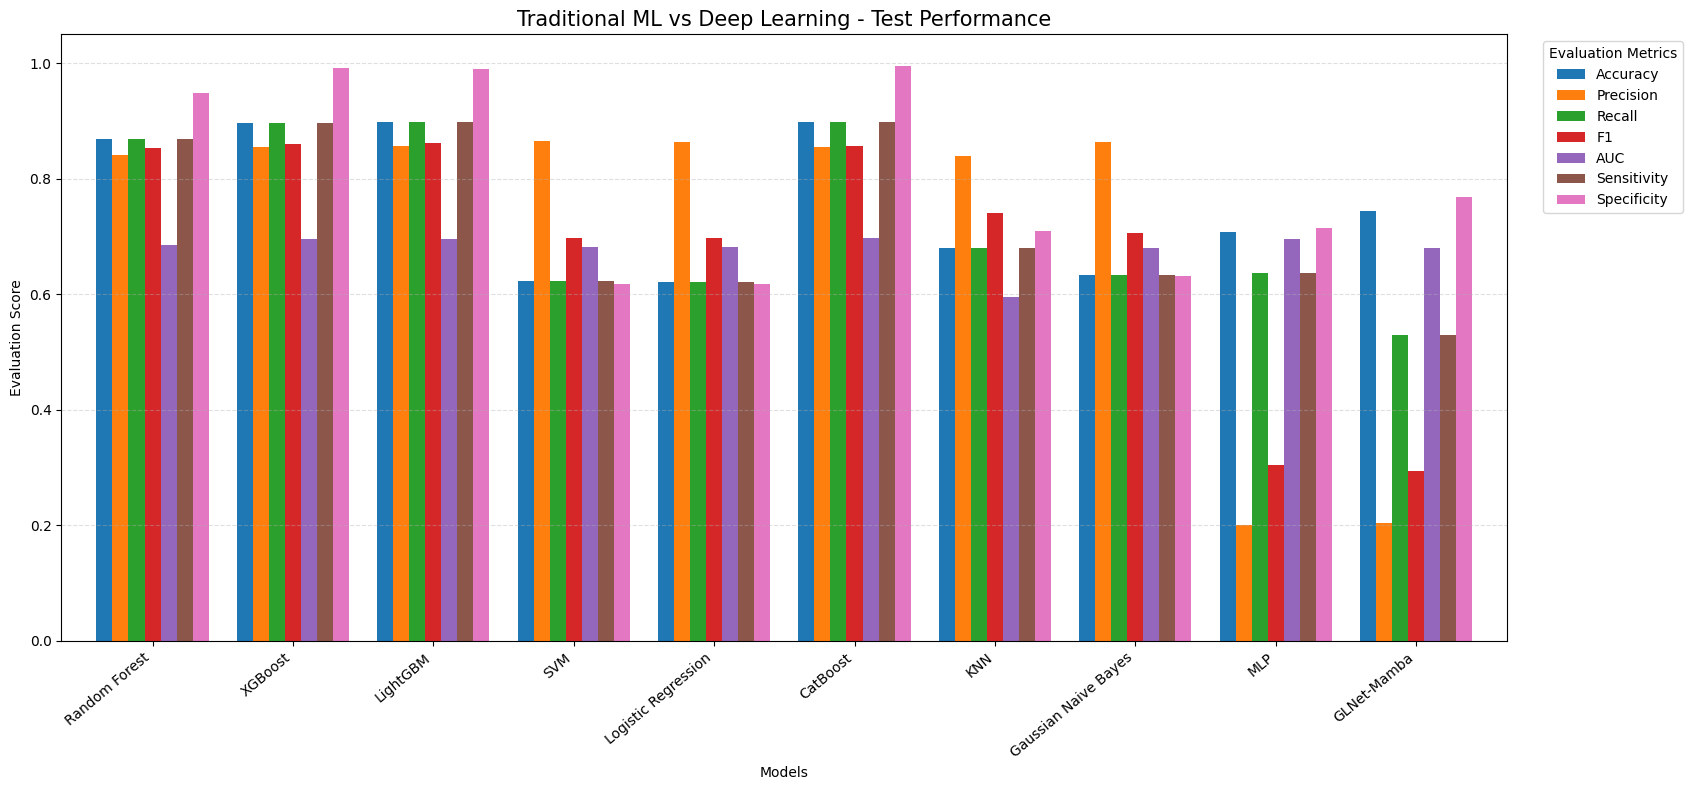

In [24]:
# ==========================================
# COMBINED MODEL PERFORMANCE CHART
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt

# Reconstruct traditional ML test results
traditional_test = model_results_df[[
    "Model",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test AUC",
    "Test Specificity"
]].copy()

traditional_test = traditional_test.rename(columns={
    "Test Accuracy": "Accuracy",
    "Test Precision": "Precision",
    "Test Recall": "Recall",
    "Test F1": "F1",
    "Test AUC": "AUC",
    "Test Specificity": "Specificity"
})
traditional_test["Sensitivity"] = traditional_test["Recall"] # Sensitivity is identical to Recall/TPR

# Reconstruct deep learning test results
deep_test = test_comparison[["Model", "Accuracy", "Precision", "Recall", "F1", "AUC", "Sensitivity", "Specificity"]].copy()

# Combine both sets of results
combined_test_results = pd.concat([traditional_test, deep_test], ignore_index=True)

# Define metrics to plot
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC", "Sensitivity", "Specificity"]

plot_data = combined_test_results.set_index("Model")[metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(17, 8),
    width=0.8
)

plt.title(
    "Traditional ML vs Deep Learning - Test Performance",
    fontsize=15
)

plt.xlabel("Models")
plt.ylabel("Evaluation Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=40, ha="right")

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Combined_Model_Performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

Training: Random Forest
Training: XGBoost
Training: LightGBM
Training: SVM
Training: Logistic Regression
Training: CatBoost
Training: KNN
Training: Gaussian Naive Bayes

All 10 models are ready for ROC analysis.


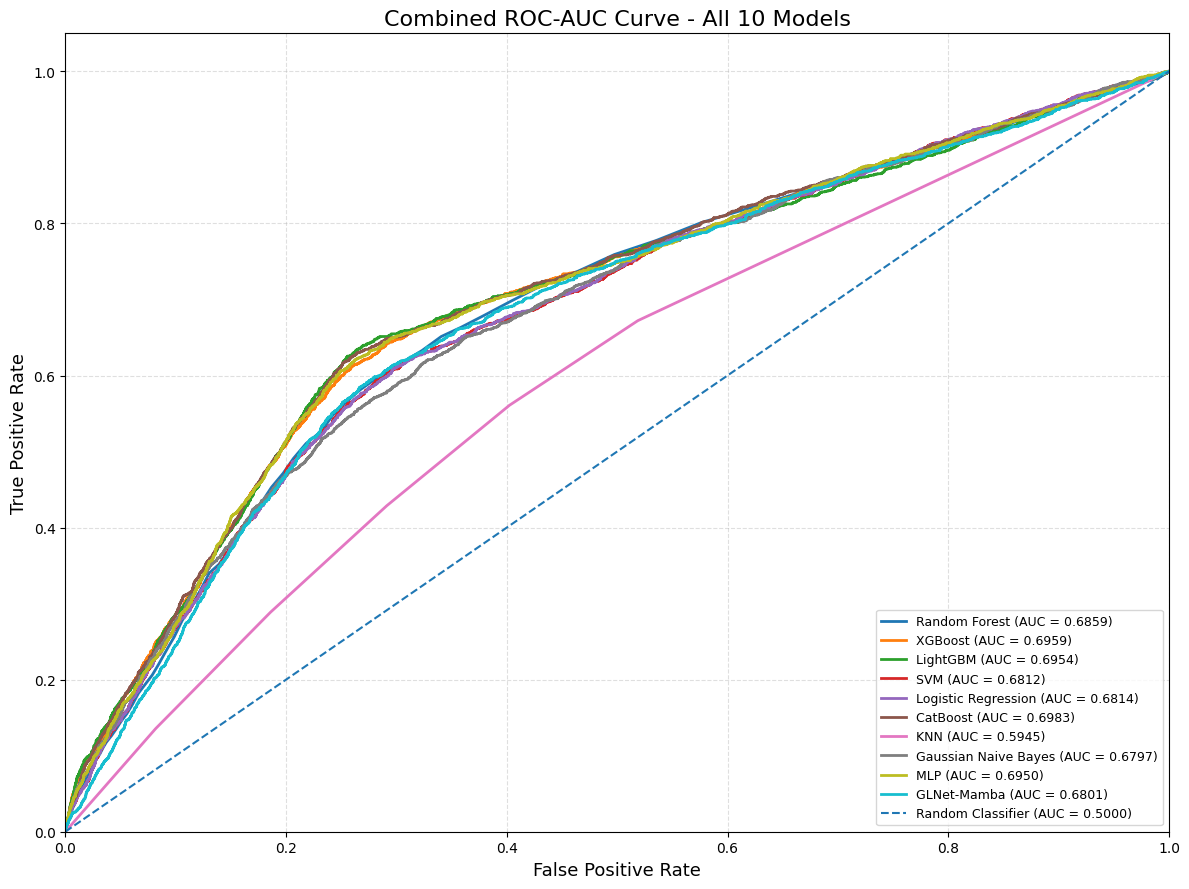


ROC-AUC COMPARISON - ALL MODELS


,Model,Test AUC,Rank
0,CatBoost,0.6983,1
1,XGBoost,0.6959,2
2,LightGBM,0.6954,3
3,MLP,0.6950,4
4,Random Forest,0.6859,5
5,Logistic Regression,0.6814,6
6,SVM,0.6812,7
7,GLNet-Mamba,0.6801,8
8,Gaussian Naive Bayes,0.6797,9
9,KNN,0.5945,10



Saved successfully:
1. Combined_ROC_AUC_All_Models.png
2. ROC_AUC_All_Models.csv
3. ROC_AUC_All_Models.xlsx


In [25]:

# ==========================================
# COMBINED ROC-AUC CURVE: ALL 10 MODELS
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

SEED = 42

OUTPUT_DIR = "."
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Store predicted probabilities for every model
all_model_probabilities = {}

# ------------------------------------------
# 1. TRADITIONAL MACHINE LEARNING MODELS
# ------------------------------------------

for model_name, model in models.items():

    print("Training:", model_name)

    model_pipeline = Pipeline([
        ("smote", SMOTE(random_state=SEED)),
        ("model", model)
    ])

    # Train using training data only
    model_pipeline.fit(
        X_train[selected_features],
        y_train
    )

    # Get probability of positive class (class 1)
    positive_class_index = list(
        model_pipeline.classes_
    ).index(1)

    test_probabilities = model_pipeline.predict_proba(
        X_test[selected_features]
    )[:, positive_class_index]

    all_model_probabilities[model_name] = test_probabilities


# ------------------------------------------
# 2. ADD MLP
# ------------------------------------------

all_model_probabilities["MLP"] = mlp_test_prob


# ------------------------------------------
# 3. ADD GLNET-MAMBA
# ------------------------------------------

all_model_probabilities["GLNet-Mamba"] = glnet_test_prob


# ------------------------------------------
# 4. CHECK PROBABILITY LENGTHS
# ------------------------------------------

for model_name, probabilities in all_model_probabilities.items():

    assert len(probabilities) == len(y_test), (
        f"Length mismatch for {model_name}"
    )

print("\nAll 10 models are ready for ROC analysis.")


# ------------------------------------------
# 5. PLOT ALL ROC CURVES
# ------------------------------------------

plt.figure(figsize=(12, 9))

roc_results = []

for model_name, probabilities in all_model_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc_value = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )

    roc_results.append({
        "Model": model_name,
        "Test AUC": auc_value
    })


# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.5000)"
)


# ------------------------------------------
# 6. FORMAT THE GRAPH
# ------------------------------------------

plt.title(
    "Combined ROC-AUC Curve - All 10 Models",
    fontsize=16
)

plt.xlabel(
    "False Positive Rate",
    fontsize=13
)

plt.ylabel(
    "True Positive Rate",
    fontsize=13
)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.grid(
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()


# Save high-resolution graph
plt.savefig(
    f"{OUTPUT_DIR}/Combined_ROC_AUC_All_Models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ------------------------------------------
# 7. CREATE AUC COMPARISON TABLE
# ------------------------------------------

roc_results_df = pd.DataFrame(roc_results)

roc_results_df = roc_results_df.sort_values(
    by="Test AUC",
    ascending=False
).reset_index(drop=True)

roc_results_df["Rank"] = range(
    1, len(roc_results_df) + 1
)

print("\nROC-AUC COMPARISON - ALL MODELS")

display(
    roc_results_df.round(4)
)


# ------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------

roc_results_df.to_csv(
    f"{OUTPUT_DIR}/ROC_AUC_All_Models.csv",
    index=False
)

roc_results_df.to_excel(
    f"{OUTPUT_DIR}/ROC_AUC_All_Models.xlsx",
    index=False
)

print("\nSaved successfully:")
print("1. Combined_ROC_AUC_All_Models.png")
print("2. ROC_AUC_All_Models.csv")
print("3. ROC_AUC_All_Models.xlsx")


Best Traditional ML: LightGBM
Best Deep Learning: MLP
SHAP observations: 1000
Background observations: 50
Total original features: 14

Calculating Traditional ML SHAP...


PermutationExplainer explainer: 1001it [00:48, 16.21it/s]                         



Calculating Deep Learning SHAP...


PermutationExplainer explainer: 1001it [00:13, 18.10it/s]                         



========== SHAP INDEPENDENCE CHECK ==========
Traditional SHAP shape: (1000, 14)
Deep SHAP shape: (1000, 14)
Maximum absolute difference: 0.30507683575923433
Mean absolute difference: 0.02110586120818863
Are SHAP arrays identical? False

========== COMBINED SHAP IMPORTANCE ==========


,Feature,Traditional ML SHAP,Deep Learning SHAP,Traditional ML (%),Deep Learning (%)
0,CGPA,0.078001,0.125909,55.076249,37.219467
1,Social_Media_Hours,0.016046,0.006560,11.329931,1.939043
2,Stress_Level,0.013913,0.017998,9.824157,5.320414
3,Sleep_Duration,0.012072,0.013719,8.524087,4.055447
4,Study_Hours,0.011617,0.010349,8.202840,3.059227
5,Physical_Activity,0.004280,0.004515,3.021959,1.334520
6,Age,0.003779,0.005935,2.668414,1.754538
7,Department_Science,0.000591,0.012519,0.417588,3.700665
8,Department_Arts,0.000542,0.012406,0.382798,3.667340
9,Department_Engineering,0.000265,0.015725,0.187456,4.648419


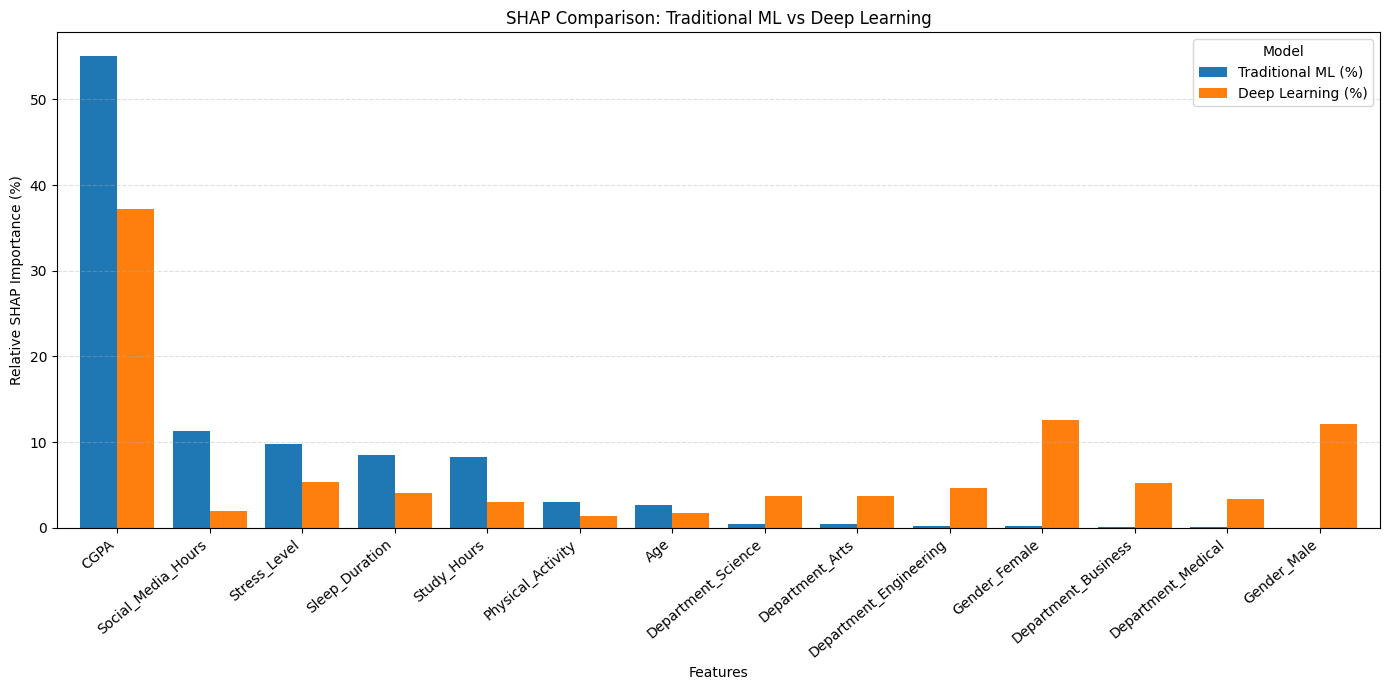


Independent SHAP calculations completed.


In [26]:

# ==========================================================
# INDEPENDENT SHAP COMPARISON:
# BEST TRADITIONAL ML VS BEST DEEP LEARNING MODEL
# ==========================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# ----------------------------------------------------------
# 1. IDENTIFY THE TWO BEST MODELS INDEPENDENTLY
# ----------------------------------------------------------

best_traditional_name = test_comparison_df.iloc[0]["Model"]
best_deep_name = test_comparison.iloc[0]["Model"]

print("Best Traditional ML:", best_traditional_name)
print("Best Deep Learning:", best_deep_name)

# Retrieve the fitted traditional ML pipeline
traditional_pipeline = fitted_models[best_traditional_name]

# ----------------------------------------------------------
# 2. USE IDENTICAL VALIDATION AND BACKGROUND OBSERVATIONS
# ----------------------------------------------------------

all_features = X_train.columns.tolist()

N_SHAP = min(1000, len(X_val))

X_shap_common = X_val.sample(
    n=N_SHAP,
    random_state=SEED
).copy()

X_background_common = X_train.sample(
    n=min(50, len(X_train)),
    random_state=SEED
).copy()

print("SHAP observations:", len(X_shap_common))
print("Background observations:", len(X_background_common))
print("Total original features:", len(all_features))

# ----------------------------------------------------------
# 3. TRADITIONAL ML PREDICTION FUNCTION
# ----------------------------------------------------------

def traditional_predict(data):

    data_df = pd.DataFrame(
        data,
        columns=all_features
    )

    probabilities = traditional_pipeline.predict_proba(
        data_df[selected_features]
    )[:, 1]

    return probabilities


# ----------------------------------------------------------
# 4. DEEP LEARNING PREDICTION FUNCTION
# ----------------------------------------------------------

if best_deep_name == "MLP":

    def deep_predict(data):

        data_df = pd.DataFrame(
            data,
            columns=all_features
        )

        return final_mlp.predict_proba(
            data_df
        )[:, 1]


elif best_deep_name == "GLNet-Mamba":

    final_glnet.eval()

    def deep_predict(data):

        data_df = pd.DataFrame(
            data,
            columns=all_features
        )

        selected_data = selector.transform(data_df)

        return predict_glnet(
            final_glnet,
            selected_data
        )

else:
    raise ValueError("Unknown deep learning model.")


# ----------------------------------------------------------
# 5. CREATE SEPARATE SHAP EXPLAINERS
# SAME METHOD, SAME DATA, SAME BACKGROUND
# ----------------------------------------------------------

masker = shap.maskers.Independent(
    X_background_common
)

MAX_EVALS = 5 * (2 * len(all_features) + 1)

# Traditional ML SHAP
print("\nCalculating Traditional ML SHAP...")

traditional_explainer = shap.Explainer(
    traditional_predict,
    masker,
    algorithm="permutation",
    seed=SEED
)

traditional_shap = traditional_explainer(
    X_shap_common,
    max_evals=MAX_EVALS
)

# Deep Learning SHAP
print("\nCalculating Deep Learning SHAP...")

deep_explainer = shap.Explainer(
    deep_predict,
    masker,
    algorithm="permutation",
    seed=SEED
)

deep_shap = deep_explainer(
    X_shap_common,
    max_evals=MAX_EVALS
)


# ----------------------------------------------------------
# 6. EXTRACT AND VALIDATE SHAP ARRAYS
# ----------------------------------------------------------

traditional_values = np.asarray(
    traditional_shap.values
)

deep_values = np.asarray(
    deep_shap.values
)

assert traditional_values.shape == deep_values.shape, (
    "SHAP dimensions do not match."
)

assert traditional_values.shape == (
    len(X_shap_common),
    len(all_features)
), "Unexpected SHAP dimensions."

assert np.isfinite(traditional_values).all()
assert np.isfinite(deep_values).all()

# ----------------------------------------------------------
# 7. CHECK WHETHER SHAP VALUES ARE REALLY IDENTICAL
# ----------------------------------------------------------

max_difference = np.max(
    np.abs(traditional_values - deep_values)
)

mean_difference = np.mean(
    np.abs(traditional_values - deep_values)
)

are_identical = np.allclose(
    traditional_values,
    deep_values,
    rtol=1e-6,
    atol=1e-8
)

print("\n========== SHAP INDEPENDENCE CHECK ==========")

print("Traditional SHAP shape:", traditional_values.shape)
print("Deep SHAP shape:", deep_values.shape)

print("Maximum absolute difference:", max_difference)
print("Mean absolute difference:", mean_difference)

print("Are SHAP arrays identical?", are_identical)

# ----------------------------------------------------------
# 8. CALCULATE INDEPENDENT FEATURE IMPORTANCE
# ----------------------------------------------------------

traditional_importance = pd.DataFrame({

    "Feature": all_features,

    "Traditional ML SHAP": np.abs(
        traditional_values
    ).mean(axis=0)

})

deep_importance = pd.DataFrame({

    "Feature": all_features,

    "Deep Learning SHAP": np.abs(
        deep_values
    ).mean(axis=0)

})

# ----------------------------------------------------------
# 9. COMBINE BOTH FEATURE IMPORTANCE TABLES
# ----------------------------------------------------------

combined_shap = pd.merge(
    traditional_importance,
    deep_importance,
    on="Feature",
    how="inner",
    validate="one_to_one"
)

# Relative importance within each model

combined_shap["Traditional ML (%)"] = (
    combined_shap["Traditional ML SHAP"] /
    combined_shap["Traditional ML SHAP"].sum()
) * 100

combined_shap["Deep Learning (%)"] = (
    combined_shap["Deep Learning SHAP"] /
    combined_shap["Deep Learning SHAP"].sum()
) * 100

combined_shap = combined_shap.sort_values(
    "Traditional ML SHAP",
    ascending=False
).reset_index(drop=True)

print("\n========== COMBINED SHAP IMPORTANCE ==========")

display(
    combined_shap.head(20).round(6)
)

# ----------------------------------------------------------
# 10. SAVE RESULTS
# ----------------------------------------------------------

combined_shap.to_csv(
    "Combined_SHAP_Importance.csv",
    index=False
)

combined_shap.to_excel(
    "Combined_SHAP_Importance.xlsx",
    index=False
)

# Save individual SHAP values

pd.DataFrame(
    traditional_values,
    columns=all_features,
    index=X_shap_common.index
).to_csv("Traditional_ML_SHAP_Values.csv")

pd.DataFrame(
    deep_values,
    columns=all_features,
    index=X_shap_common.index
).to_csv("Deep_Learning_SHAP_Values.csv")


# ----------------------------------------------------------
# 11. COMPARE RELATIVE FEATURE IMPORTANCE
# ----------------------------------------------------------

plot_shap = combined_shap.set_index("Feature")[
    ["Traditional ML (%)", "Deep Learning (%)"]
]

plot_shap = plot_shap.sort_values(
    "Traditional ML (%)",
    ascending=False
).head(15)

ax = plot_shap.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title(
    "SHAP Comparison: Traditional ML vs Deep Learning"
)

plt.xlabel("Features")
plt.ylabel("Relative SHAP Importance (%)")

plt.xticks(rotation=40, ha="right")

plt.legend(title="Model")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    "Combined_SHAP_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nIndependent SHAP calculations completed.")


Traditional ML SHAP saved: (1000, 14)
Deep learning SHAP saved: (1000, 14)
Traditional ML observations: 1000
Deep Learning observations: 1000


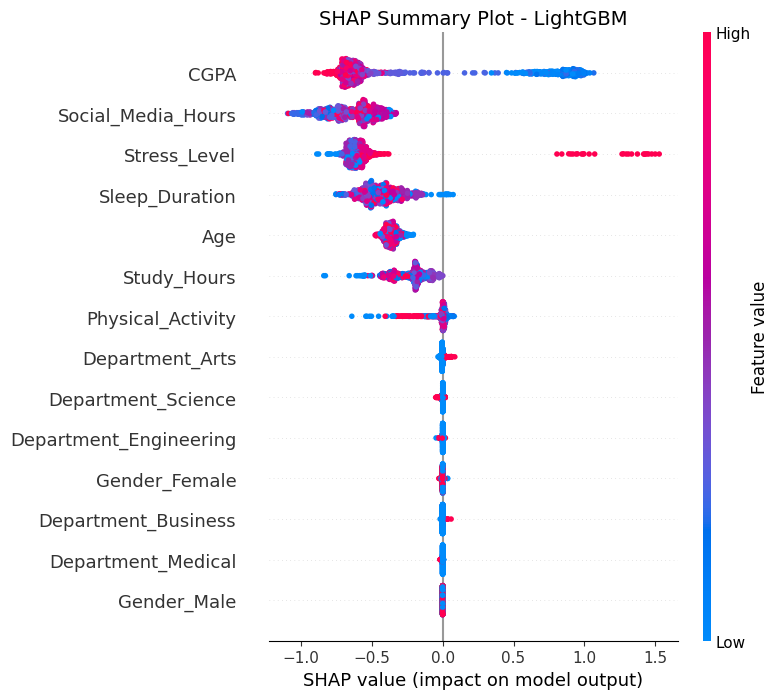

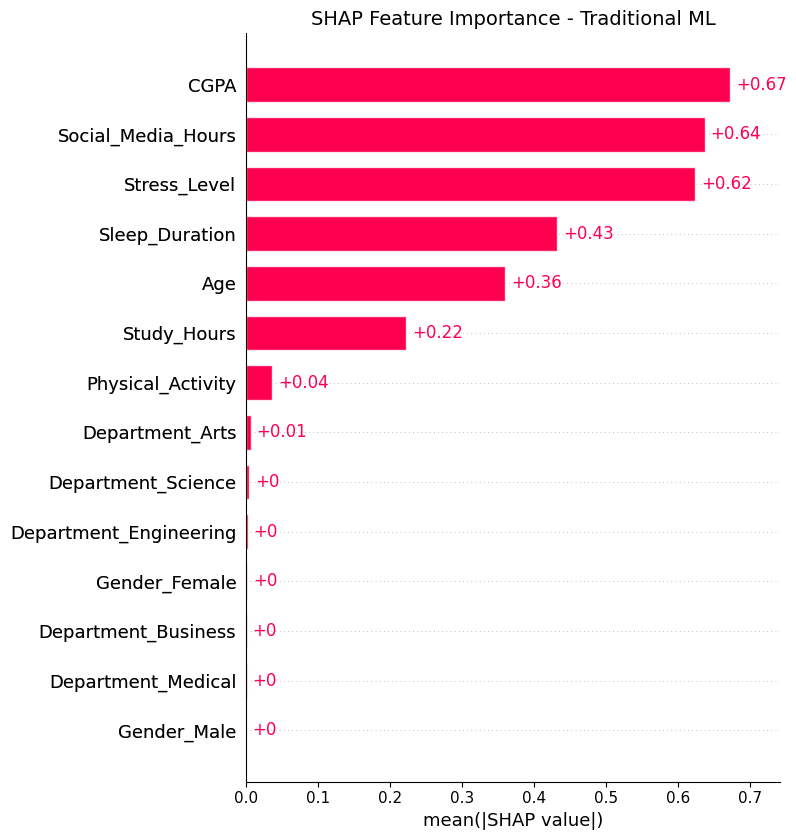

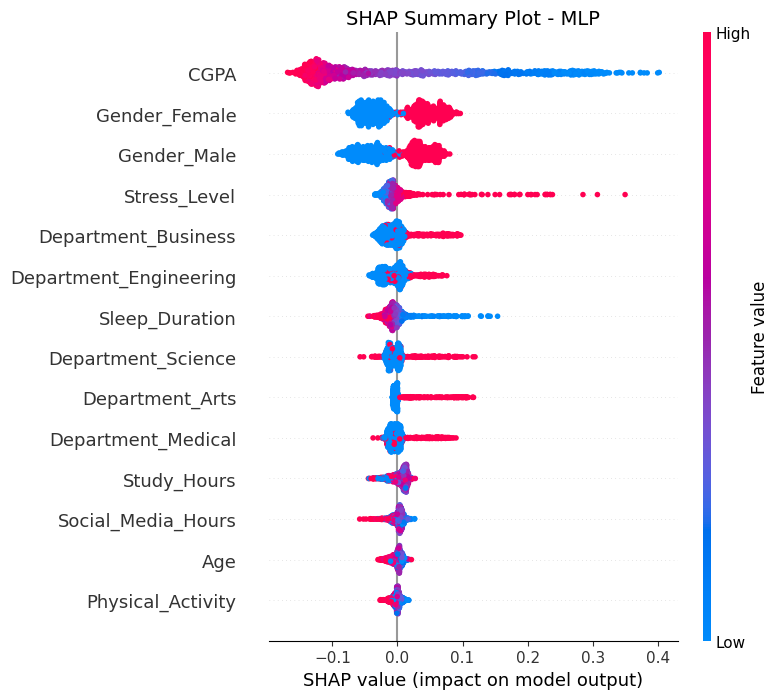

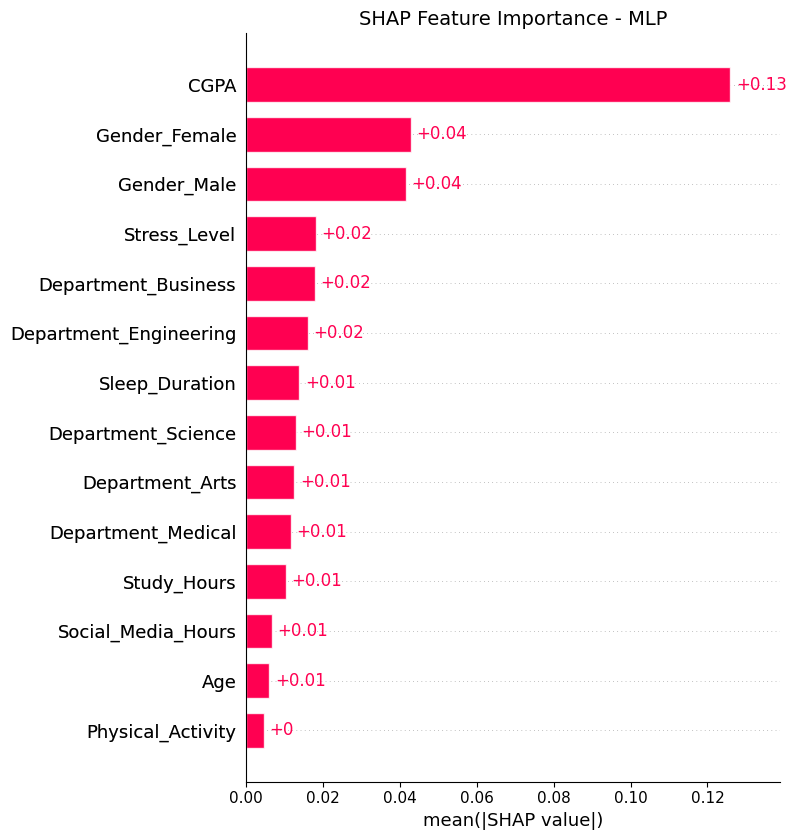

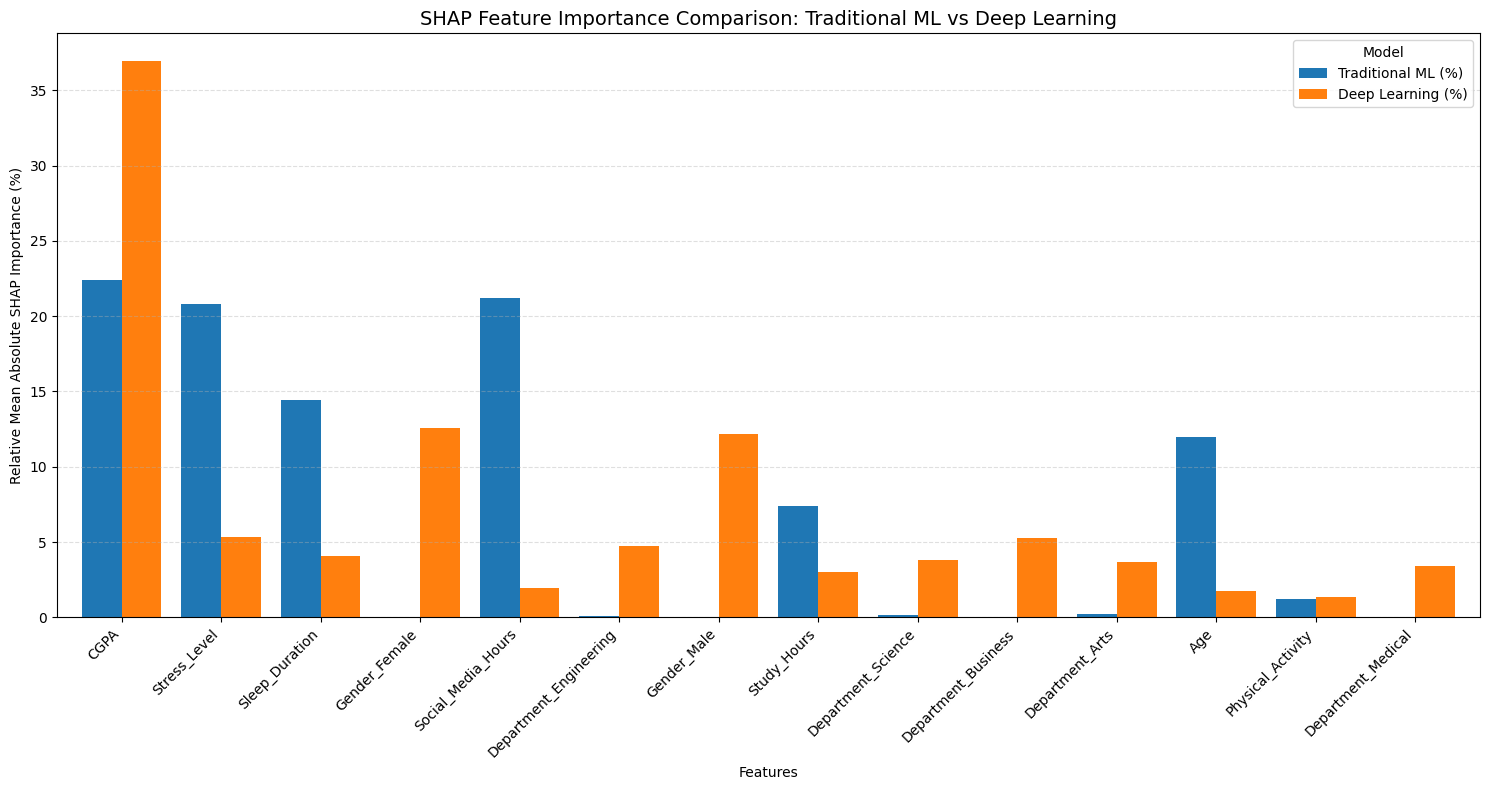


SHAP analysis completed successfully.
Traditional model: LightGBM
Deep learning model: MLP

Top 20 SHAP features:


,Feature,Traditional ML SHAP,Deep Learning SHAP,Traditional ML (%),Deep Learning (%),Average Rank
1,CGPA,0.672336,0.125969,22.417956,36.937191,1.0
6,Stress_Level,0.623496,0.018133,20.789475,5.316925,3.5
2,Sleep_Duration,0.432285,0.013882,14.413850,4.070442,5.5
7,Gender_Female,0.001366,0.042830,0.045549,12.558662,6.5
4,Social_Media_Hours,0.636700,0.006670,21.229757,1.955920,7.0
11,Department_Engineering,0.002114,0.016057,0.070476,4.708231,8.0
8,Gender_Male,0.000000,0.041486,0.000000,12.164760,8.5
3,Study_Hours,0.222369,0.010375,7.414551,3.042150,8.5
13,Department_Science,0.004620,0.012970,0.154035,3.803239,8.5
10,Department_Business,0.000945,0.017855,0.031508,5.235425,8.5



All SHAP graphs saved in: .


In [27]:
# Preserve traditional ML SHAP results before other sections overwrite variables
traditional_shap = shap_values_positive
traditional_X = X_shap.copy()

print("Traditional ML SHAP saved:",
      traditional_shap.values.shape)

# Preserve deep learning SHAP results
deep_shap = shap_values
deep_X = X_shap_display.copy()
best_deep_name = best_model_name

print("Deep learning SHAP saved:",
      deep_shap.values.shape)


# =====================================================
# SHAP GRAPHS: TRADITIONAL ML VS DEEP LEARNING
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

os.makedirs(OUTPUT_DIR, exist_ok=True)

# -----------------------------------------------------
# 1. EXTRACT SHAP ARRAYS AND FEATURE NAMES
# -----------------------------------------------------

traditional_values = np.asarray(traditional_shap.values)
deep_values = np.asarray(deep_shap.values)

traditional_features = list(traditional_X.columns)
deep_features = list(deep_X.columns)

# Check dimensions
assert traditional_values.ndim == 2, "Traditional SHAP must be 2D"
assert deep_values.ndim == 2, "Deep SHAP must be 2D"

assert traditional_values.shape[1] == len(traditional_features)
assert deep_values.shape[1] == len(deep_features)

assert traditional_values.shape[0] == len(traditional_X)
assert deep_values.shape[0] == len(deep_X)

print("Traditional ML observations:", len(traditional_values))
print("Deep Learning observations:", len(deep_values))

# -----------------------------------------------------
# 2. TRADITIONAL ML SHAP SUMMARY PLOT
# -----------------------------------------------------

traditional_explanation = shap.Explanation(
    values=traditional_values,
    data=traditional_X.to_numpy(),
    feature_names=traditional_features
)

plt.figure(figsize=(12, 8))

shap.plots.beeswarm(
    traditional_explanation,
    max_display=20,
    show=False
)

plt.title(
    f"SHAP Summary Plot - {best_traditional_name}",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Traditional_ML_SHAP_Summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Traditional ML feature importance

plt.figure(figsize=(12, 8))

shap.plots.bar(
    traditional_explanation,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Feature Importance - Traditional ML",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Traditional_ML_SHAP_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# -----------------------------------------------------
# 3. DEEP LEARNING SHAP SUMMARY PLOT
# -----------------------------------------------------

deep_explanation = shap.Explanation(
    values=deep_values,
    data=deep_X.to_numpy(),
    feature_names=deep_features
)

plt.figure(figsize=(12, 8))

shap.plots.beeswarm(
    deep_explanation,
    max_display=20,
    show=False
)

plt.title(
    f"SHAP Summary Plot - {best_deep_name}",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Deep_Learning_SHAP_Summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Deep learning feature importance

plt.figure(figsize=(12, 8))

shap.plots.bar(
    deep_explanation,
    max_display=20,
    show=False
)

plt.title(
    f"SHAP Feature Importance - {best_deep_name}",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Deep_Learning_SHAP_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# -----------------------------------------------------
# 4. CALCULATE MEAN ABSOLUTE SHAP IMPORTANCE
# -----------------------------------------------------

traditional_importance = pd.DataFrame({
    "Feature": traditional_features,
    "Traditional ML SHAP": np.abs(
        traditional_values
    ).mean(axis=0)
})

deep_importance = pd.DataFrame({
    "Feature": deep_features,
    "Deep Learning SHAP": np.abs(
        deep_values
    ).mean(axis=0)
})

# Compare only features present in both models
combined_shap = pd.merge(
    traditional_importance,
    deep_importance,
    on="Feature",
    how="inner"
)

if combined_shap.empty:
    raise ValueError(
        "There are no common feature names to compare."
    )

# -----------------------------------------------------
# 5. NORMALIZE SHAP IMPORTANCE
# -----------------------------------------------------

combined_shap["Traditional ML (%)"] = (
    combined_shap["Traditional ML SHAP"] /
    traditional_importance["Traditional ML SHAP"].sum()
) * 100

combined_shap["Deep Learning (%)"] = (
    combined_shap["Deep Learning SHAP"] /
    deep_importance["Deep Learning SHAP"].sum()
) * 100

# Rank features across both models
combined_shap["Average Rank"] = (
    combined_shap["Traditional ML SHAP"].rank(
        ascending=False
    ) +
    combined_shap["Deep Learning SHAP"].rank(
        ascending=False
    )
) / 2

top_features = combined_shap.sort_values(
    "Average Rank"
).head(20)

# -----------------------------------------------------
# 6. COMBINED SHAP COMPARISON GRAPH
# -----------------------------------------------------

plot_data = top_features.set_index("Feature")[
    ["Traditional ML (%)", "Deep Learning (%)"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(15, 8),
    width=0.8
)

plt.title(
    "SHAP Feature Importance Comparison: Traditional ML vs Deep Learning",
    fontsize=14
)

plt.xlabel("Features")
plt.ylabel("Relative Mean Absolute SHAP Importance (%)")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Model")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Combined_SHAP_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# -----------------------------------------------------
# 7. SAVE SHAP RESULTS
# -----------------------------------------------------

combined_shap.to_csv(
    f"{OUTPUT_DIR}/Combined_SHAP_Importance.csv",
    index=False
)

traditional_importance.to_csv(
    f"{OUTPUT_DIR}/Traditional_ML_SHAP_Importance.csv",
    index=False
)

deep_importance.to_csv(
    f"{OUTPUT_DIR}/Deep_Learning_SHAP_Importance.csv",
    index=False
)

print("\nSHAP analysis completed successfully.")
print("Traditional model:", best_traditional_name)
print("Deep learning model:", best_deep_name)

print("\nTop 20 SHAP features:")
display(top_features)

print("\nAll SHAP graphs saved in:", OUTPUT_DIR)

In [ ]:
# ==========================================
# SAVE FINAL RESEARCH OUTPUTS
# ==========================================

import shutil

shutil.make_archive(
    "Combined_ML_DL_Research_Results",
    "zip",
    OUTPUT_DIR
)

print("All results saved successfully.")

print("Files include:")
print("- Combined test metrics CSV and Excel")
print("- Combined model performance chart")
print("- Combined SHAP importance CSV and Excel")
print("- SHAP comparison chart")
print("- Traditional ML SHAP summary")
print("- Deep learning SHAP summary")

from google.colab import files

files.download("Combined_ML_DL_Research_Results.zip")